In [1]:
from utils import load_counties, set_plot_style, NRI_HAZARD_NAMES

import pandas as pd
import numpy as np
import geopandas as gpd

import statsmodels.formula.api as smf
import statsmodels.api as sm

from scipy import stats

import patsy

from statsmodels.iolib.summary2 import summary_col
from scipy.stats import spearmanr

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
import matplotlib as mpl

import pickle

import scipy

In [2]:
set_plot_style()


In [3]:
nri_county=pd.read_parquet("../data_loaded/nri_counties.parquet")

In [4]:
counties = load_counties()


### Treatment - CBSA

In [5]:
results_all=pd.read_csv('../data_generated/cf_results/cf_summary.csv')

In [6]:
df = results_all.copy()

df["hazard"] = df["hazard"].map(NRI_HAZARD_NAMES)

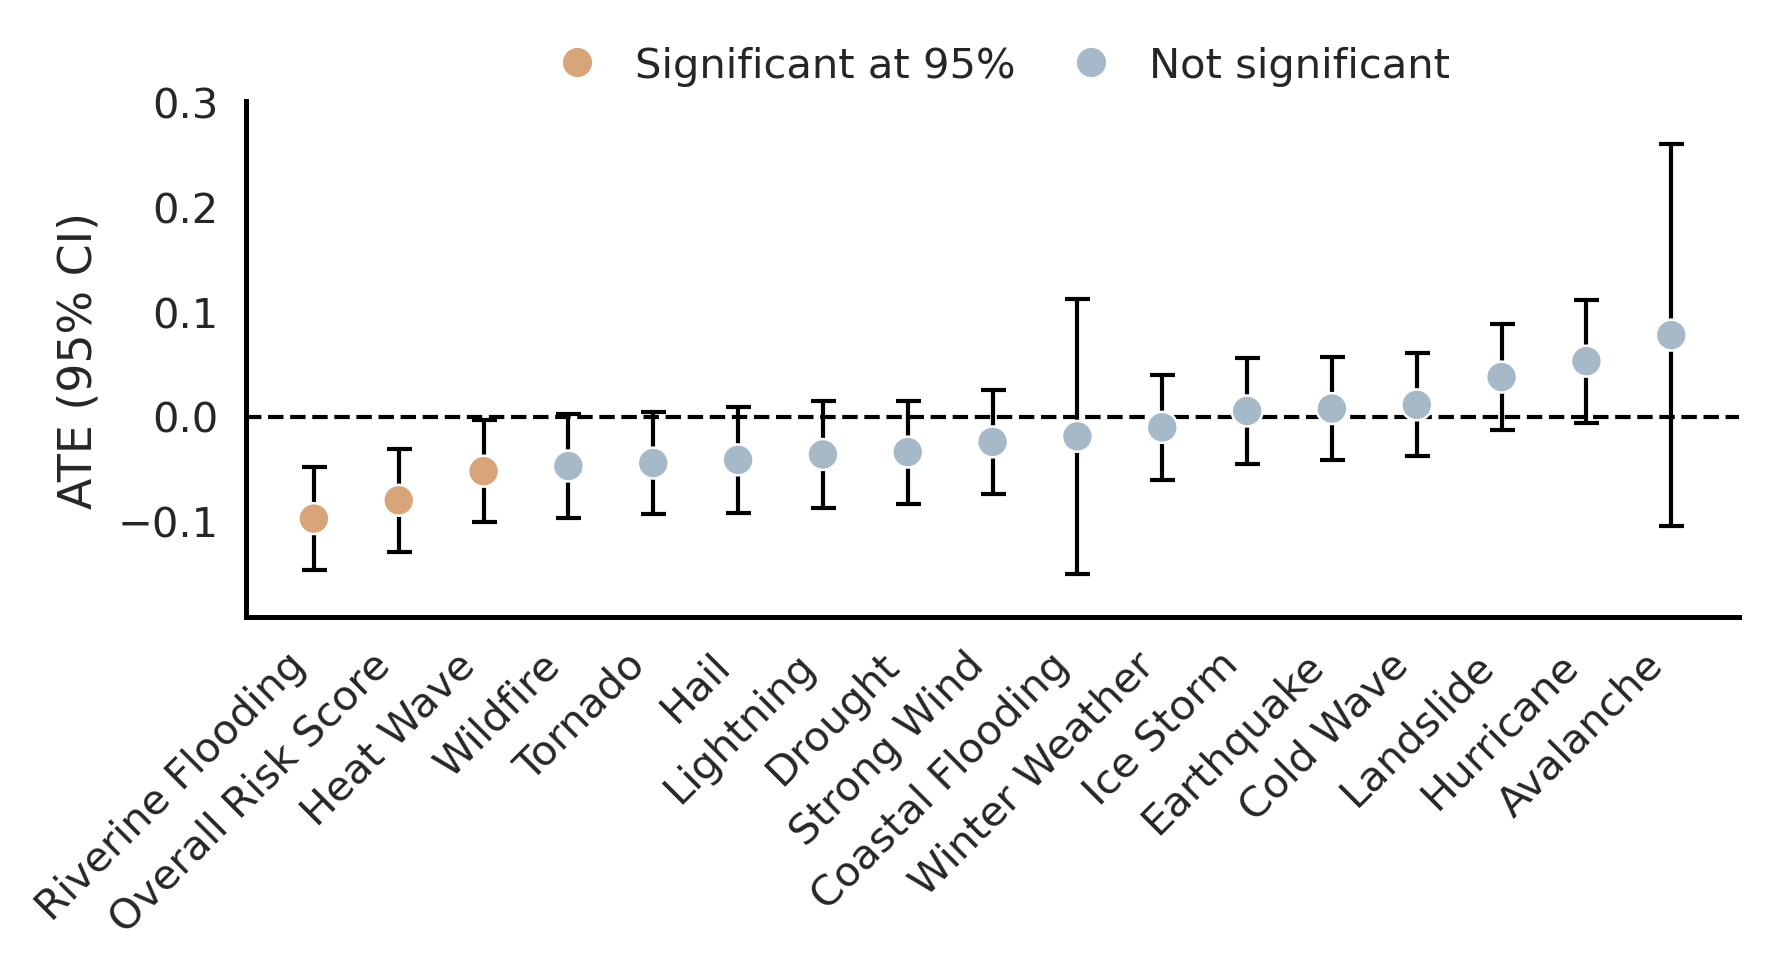

In [7]:
# keep hazards with ATE estimates
df = df[["hazard", "ATE_est", "ATE_se", "ATE_p"]].dropna().copy()

# 95% CI
z95 = 1.96
df["ci95_low"]  = df["ATE_est"] - z95 * df["ATE_se"]
df["ci95_high"] = df["ATE_est"] + z95 * df["ATE_se"]

# significance at 95%: CI excludes 0
df["sig95"] = (df["ci95_low"] > 0) | (df["ci95_high"] < 0)

# sort left->right by ATE
df = df.sort_values("ATE_est", ascending=True).reset_index(drop=True)

x = np.arange(len(df))

# ---- plot ----
fig, ax = plt.subplots(figsize=(6, 3.5))
# fig, ax = plt.subplots(figsize=(6, 4))

# colors (muted)
c_nonsig = "#A5B9C8"  # muted blue
c_sig    = "#D8A57A"  # muted orange

colors = np.where(df["sig95"], c_sig, c_nonsig)

# vertical CI bars (because disasters are on x-axis)
yerr = z95 * df["ATE_se"].to_numpy()

ax.errorbar(
    x=x,
    y=df["ATE_est"].to_numpy(),
    yerr=yerr,
    fmt="o",
    markersize=6,
    capsize=3,
    linewidth=1,
    color="black", 
    ecolor="black",
    zorder=2
)

# overlay colored points to indicate significance
ax.scatter(
    x,
    df["ATE_est"].to_numpy(),
    s=55,
    c=colors,
    edgecolors="white",
    linewidths=0.6,
    zorder=3
)

# zero line
ax.axhline(0, linewidth=1.0, linestyle="--", color="black")

# x labels (hazards)
ax.set_xticks(x)
ax.set_xticklabels(df["hazard"], rotation=45, ha="right")

ax.set_ylabel("ATE (95% CI)")

# y-limits with padding
ymin = (df["ci95_low"]).min()
ymax = (df["ci95_high"]).max()
pad = 0.10 * (ymax - ymin) if ymax > ymin else 0.1
ax.set_ylim(ymin - pad, ymax + pad)

# minimalist styling
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

# legend (top, horizontal)
from matplotlib.lines import Line2D
handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=c_sig, markeredgecolor="white",
           markersize=8, label="Significant at 95%"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=c_nonsig, markeredgecolor="white",
           markersize=8, label="Not significant")
]
ax.legend(
    handles=handles,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=2,
    columnspacing=0.8,
    handletextpad=0.4
)

plt.tight_layout()
plt.show()

In [8]:
cates_all=pd.read_csv('../data_generated/cf_results/cf_cates.csv')
cates_all=cates_all[cates_all['hazard']=='RISK_SCORE']

In [9]:
vmax = cates_all["cate"].abs().quantile(0.95)
vmin = -vmax

norm = TwoSlopeNorm(
    vmin=vmin,
    vcenter=0.0,
    vmax=vmax
)

/tmp/ipykernel_17001/2895249298.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap("RdYlBu_r")


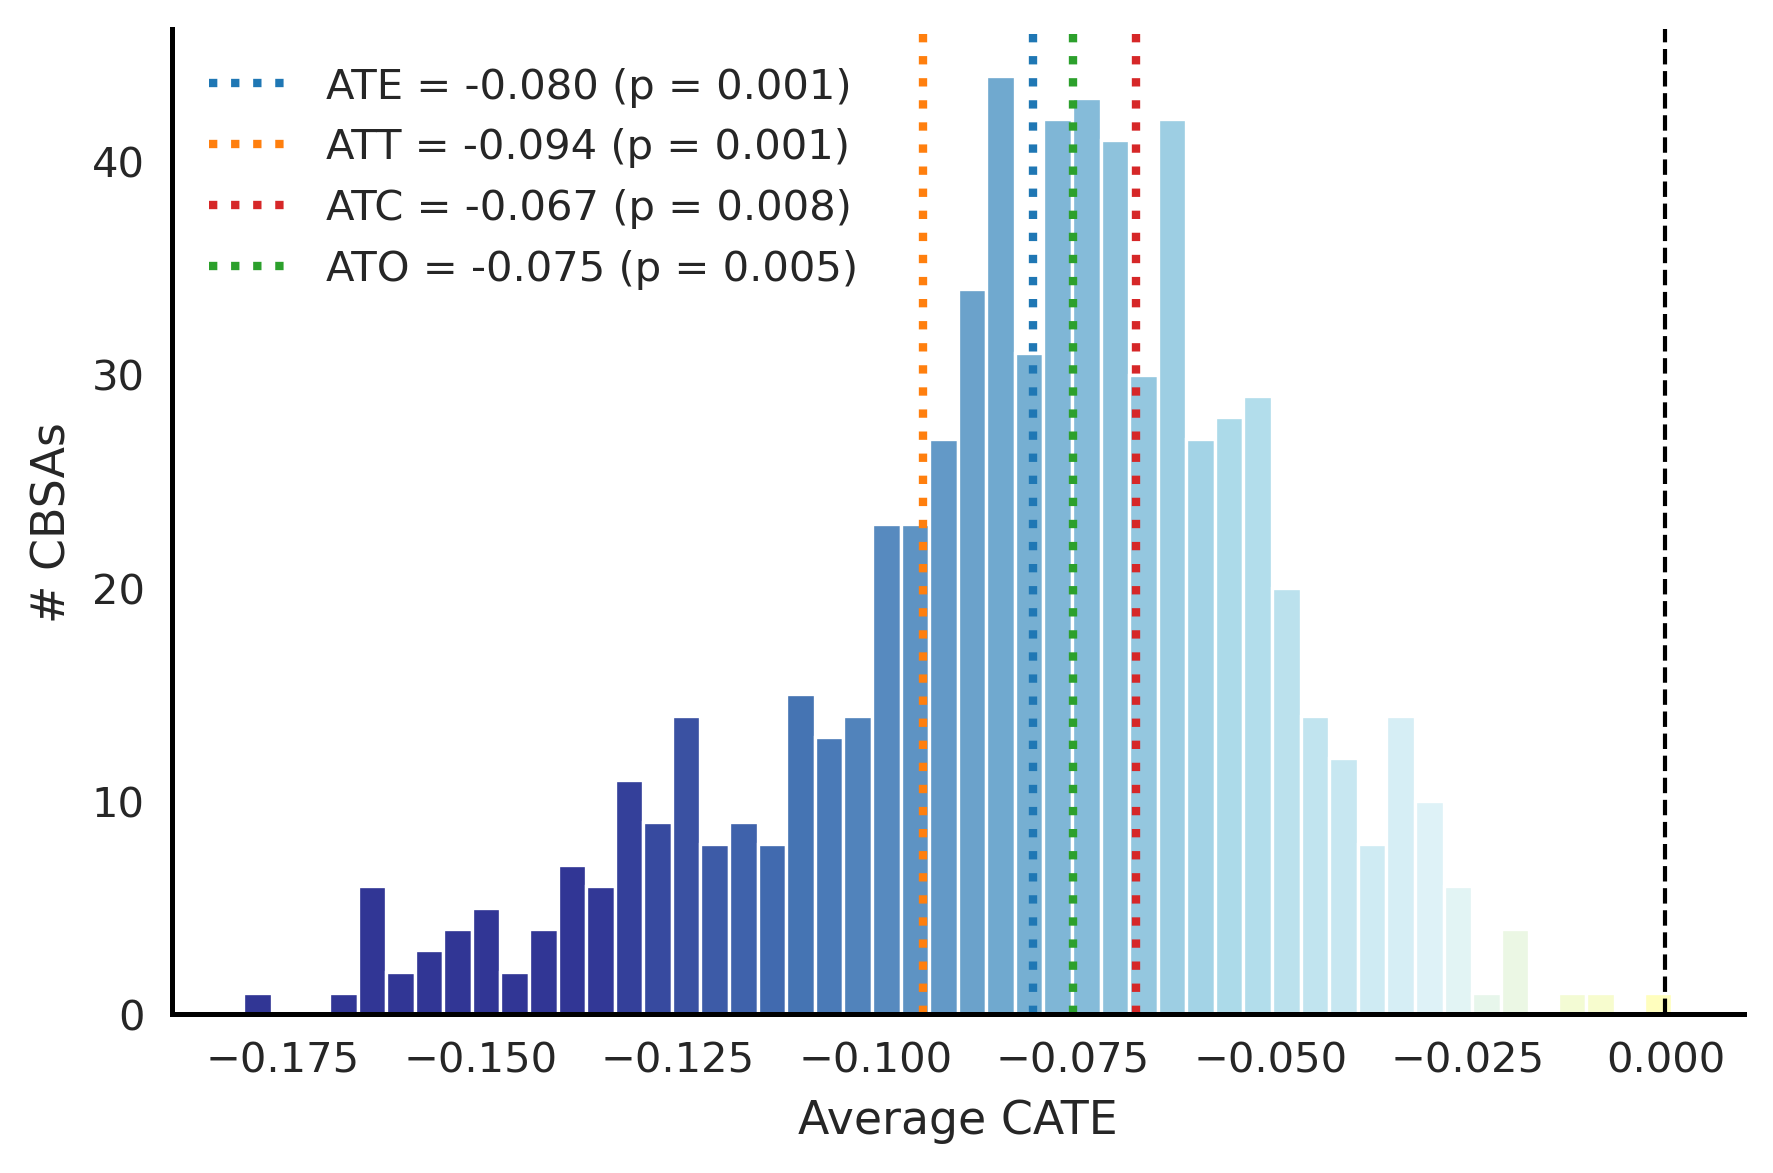

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
# fig, ax = plt.subplots(figsize=(6, 6))

vals = cates_all["cate"].values

counts, bin_edges = np.histogram(vals, bins=50)

# compute bin midpoints (for color mapping)
bin_mids = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# get colors using the SAME norm + cmap as your colorbar
cmap = mpl.cm.get_cmap("RdYlBu_r")
colors = cmap(norm(bin_mids))

# plot histogram bars one by one
for left, height, width, color in zip(bin_edges[:-1], counts,
                                      np.diff(bin_edges), colors):
    ax.bar(left, height, width=width,
           color=color, edgecolor="white")

# zero line
ax.axvline(0, color="black", linewidth=1, linestyle="--")

ate=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATE_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATE_p'].iloc[0], 3)
ax.axvline(ate, lw=2, linestyle=":",
           label=f"ATE = {ate:.3f} (p = {p_val:.3f})",
           color="tab:blue")

att=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATT_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATT_p'].iloc[0], 3)
ax.axvline(att, lw=2, linestyle=":",
           label=f"ATT = {att:.3f} (p = {p_val:.3f})",
           color="tab:orange")

atc=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATC_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATC_p'].iloc[0], 3)
ax.axvline(atc, lw=2, linestyle=":",
           label=f"ATC = {atc:.3f} (p = {p_val:.3f})",
           color="tab:red")

ato=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATO_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATO_p'].iloc[0], 3)
ax.axvline(ato, lw=2, linestyle=":",
           label=f"ATO = {ato:.3f} (p = {p_val:.3f})",
           color="tab:green")

# labels and theme
ax.set_xlabel("Average CATE")
ax.set_ylabel("# CBSAs")
ax.set_title("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()

plt.show()

In [11]:
variable_importance=pd.read_csv('../data_generated/cf_results/cf_varimp.csv')
variable_importance=variable_importance[variable_importance['hazard']=='RISK_SCORE']

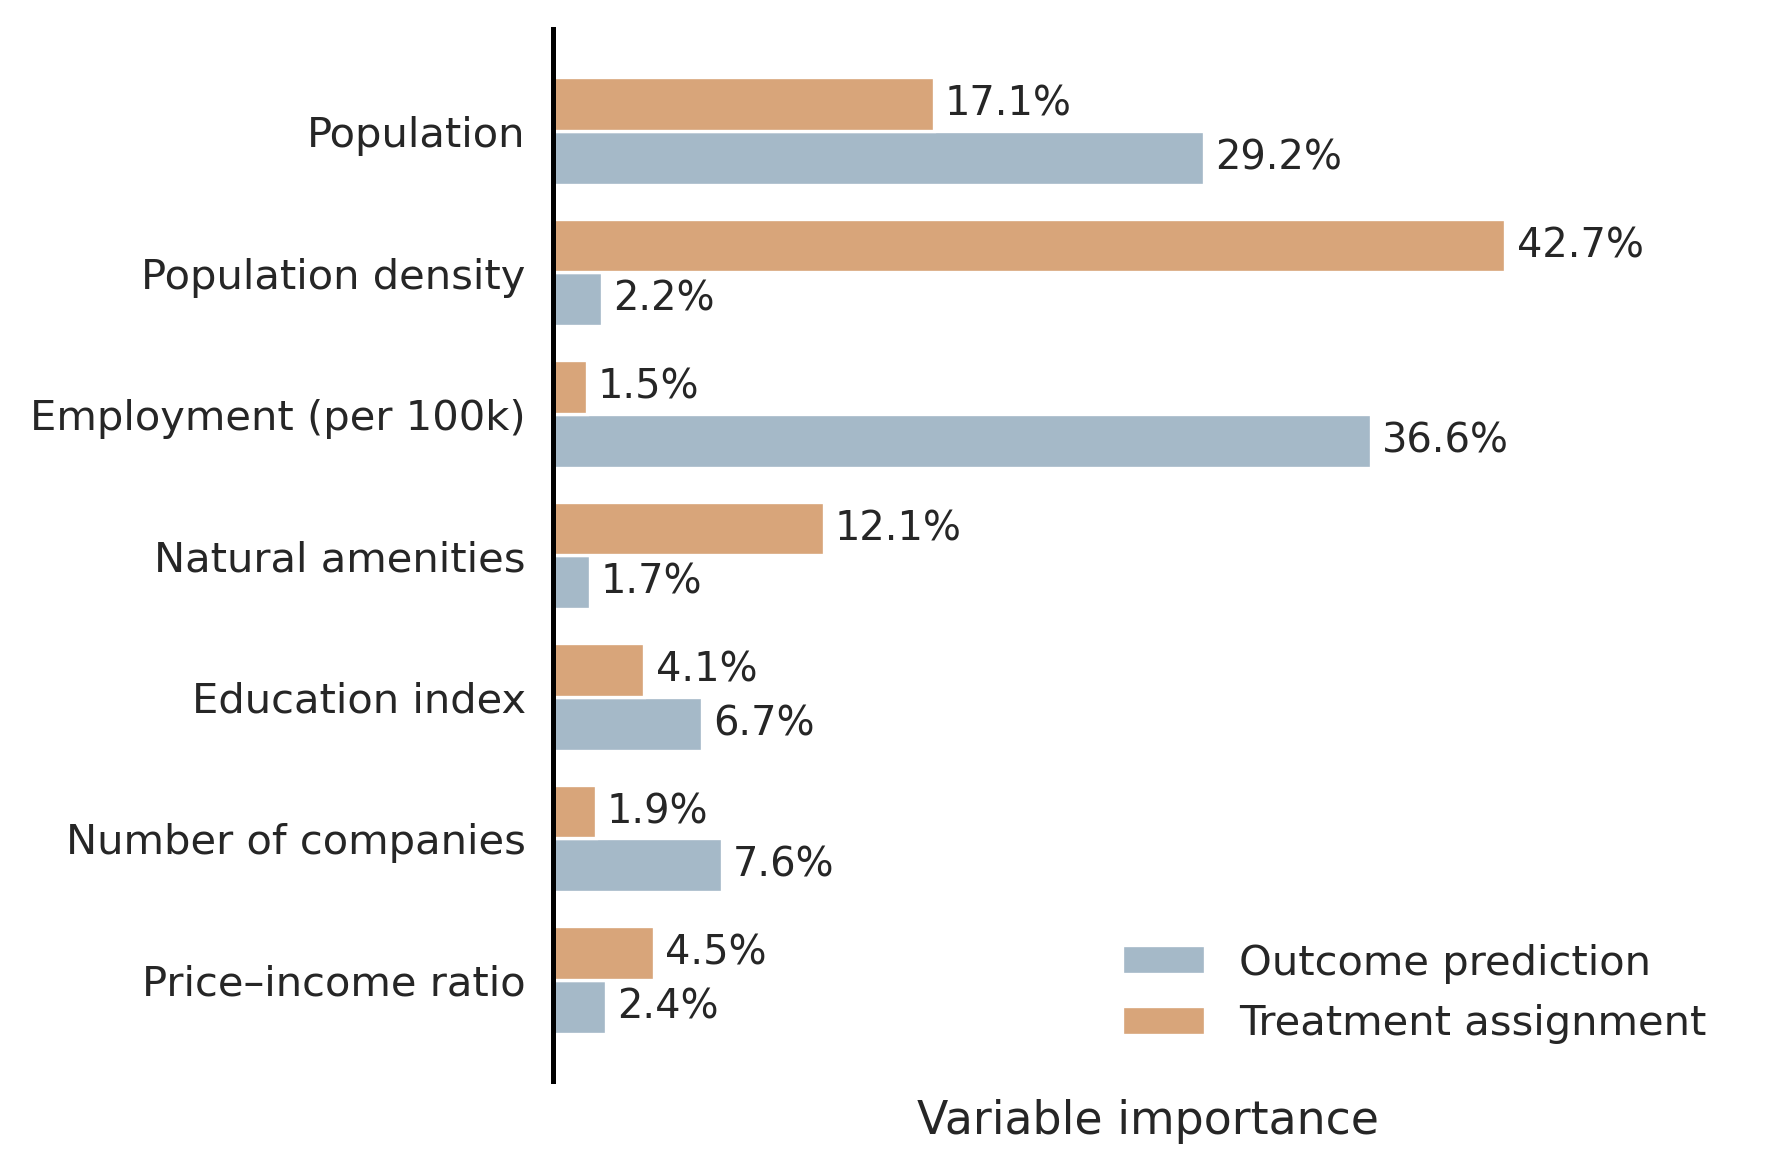

In [12]:
# Rename variables for readability
rename_map = {
    "nat_amenity_score": "Natural amenities",
    "state": "State FE",
    "income_price_ratio2023": "Price–income ratio",
    "gdp_pc": "GDP pc",
    "income_index_adj": "Income index",
    "real_estate_taxes_med": "Property taxes",
    "est_100k": "Number of companies",
    "POPULATION": "Population",
    "health_index_adj": "Health index",
    "personal_income_pc": "Personal income pc",
    "inequality_ratio": "Inequality ratio",
    "education_index": "Education index",
    "n_postings_100k": "Job postings (per 100k)",
    "emp_100k": "Employment (per 100k)",
    "poverty_rate_all": "Poverty rate",
    "pop_density": "Population density",
    "dividends_pc": "Dividends pc"
}

# keep only the two nuisance models
df = variable_importance.copy()
df = df[(df["hazard"] == "RISK_SCORE") & (df["model"].isin(["Y_nuisance", "W_nuisance"]))]

# mean importance by nuisance x variable
imp = (
    df.groupby(["model", "variable"], as_index=False)["importance"]
      .mean()
)

# top-7 variables by overall mean across nuisances
top_vars = (
    imp.groupby("variable")["importance"]
       .mean()
       .sort_values(ascending=False)
       .head(7)
       .index
)

imp_top = imp[imp["variable"].isin(top_vars)].copy()

# nice names + pivot wide for plotting
imp_top["variable_name"] = imp_top["variable"].map(lambda v: rename_map.get(v, v))

wide = (
    imp_top.pivot_table(index="variable_name", columns="model", values="importance", aggfunc="mean")
           .fillna(0.0)
)

# ensure consistent column order
for col in ["Y_nuisance", "W_nuisance"]:
    if col not in wide.columns:
        wide[col] = 0.0
wide = wide[["Y_nuisance", "W_nuisance"]]

# order: smallest at top for barh (so reverse later if you want)
wide["overall"] = wide.mean(axis=1)
wide = wide.sort_values("overall", ascending=True).drop(columns="overall")

# ---- Plot: grouped horizontal bars ----
fig, ax = plt.subplots(figsize=(6, 4))

y = np.arange(len(wide.index))
h = 0.38

vals_y = wide["Y_nuisance"].values * 100
vals_w = wide["W_nuisance"].values * 100

ax.barh(y - h/2, vals_y, height=h, label="Outcome prediction", color="#A5B9C8")
ax.barh(y + h/2, vals_w, height=h, label="Treatment assignment", color="#D8A57A")

# labels on bars
for i, v in enumerate(vals_y):
    ax.text(v + 0.5, y[i] - h/2, f"{v:.1f}%", va="center")
for i, v in enumerate(vals_w):
    ax.text(v + 0.5, y[i] + h/2, f"{v:.1f}%", va="center")

ax.set_yticks(y)
ax.set_yticklabels(wide.index)
ax.set_xlabel("Variable importance")

xmax = max(vals_y.max(), vals_w.max())
ax.set_xlim(0, xmax * 1.25)

ax.legend(frameon=False, loc="lower right")

# REMOVE x-axis ticks
ax.set_xticks([])

sns.despine(left=False, bottom=True)

plt.tight_layout()
plt.show()

In [13]:
subgroups=pd.read_csv('../data_generated/cf_results/cf_subgroups.csv')
subgroups=subgroups[subgroups['hazard']=='RISK_SCORE']

In [14]:
# ---- Rename variables for readability ----
rename_map = {
    "Natural Amenities": "Natural amenities",
    "Population Density": "Population density",
    "Price-Income": "Price–income ratio",
    "GDP per Capita": "GDP pc",
    "income_index_adj": "Income index",
    "real_estate_taxes_med": "Property taxes",
    "est_100k": "Number of companies",
    "Population": "Population",
    "health_index_adj": "Health index",
    "personal_income_pc": "Personal income pc",
    "inequality_ratio": "Inequality ratio",
    "Education Index": "Education index",
    "n_postings_100k": "Job postings (per 100k)",
    "Number of Employed": "Employment (per 100k)",
    "poverty_rate_all": "Poverty rate",
    "pop_density": "Population density",
    "dividends_pc": "Dividends pc"
}

subgroups["moderator"] = subgroups["moderator"].map(lambda v: rename_map.get(v, v))

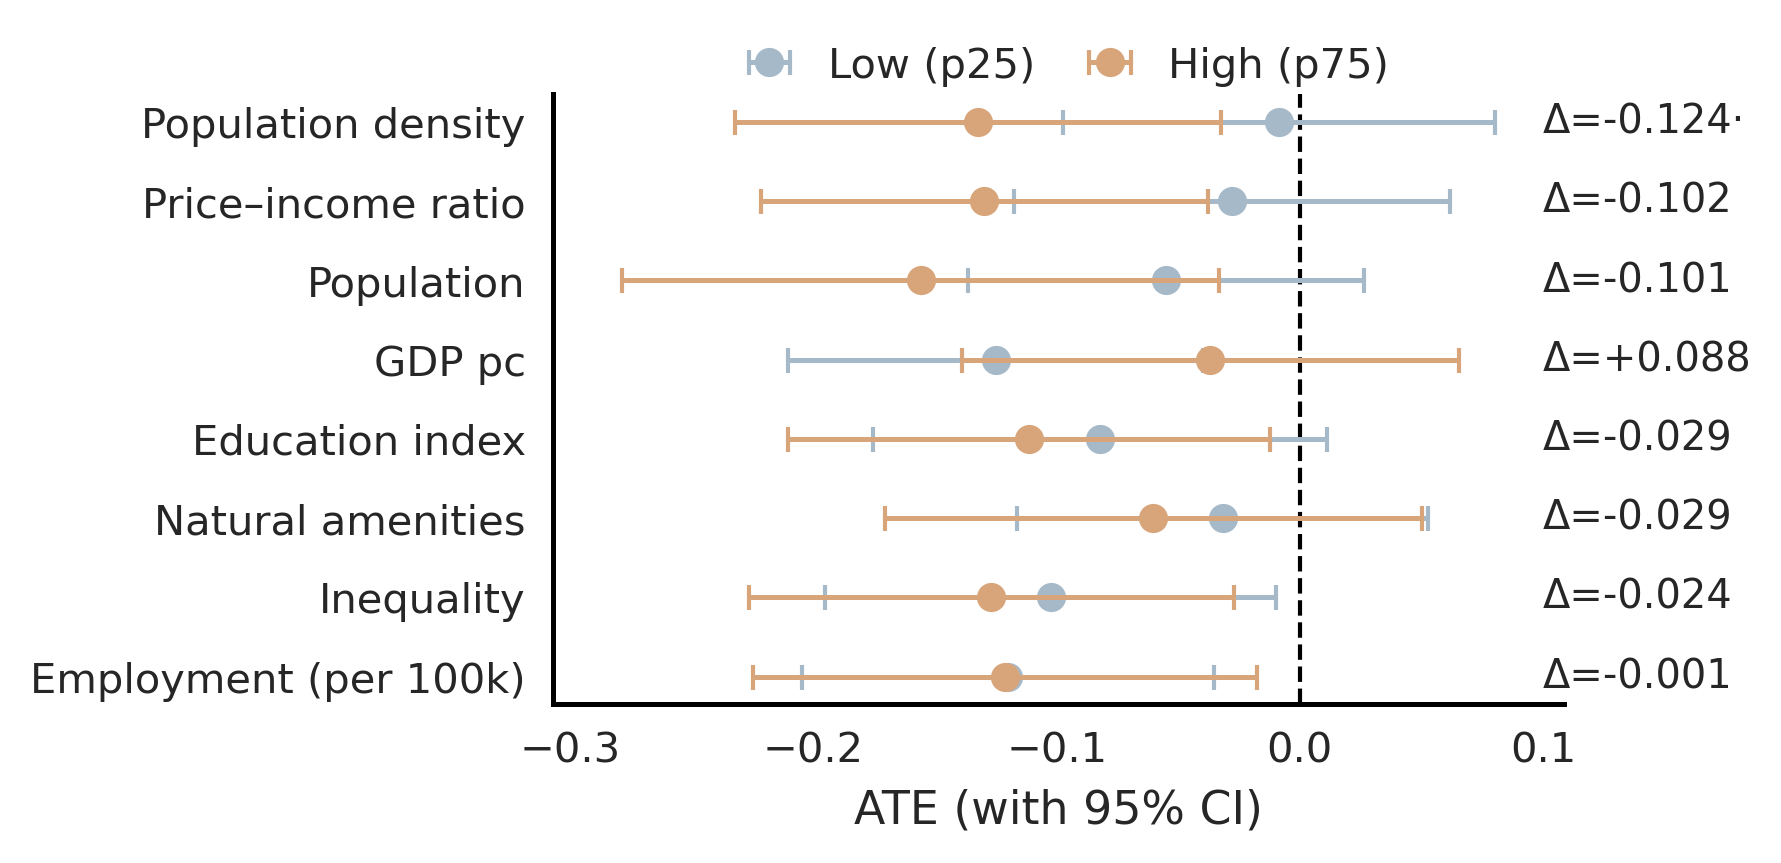

In [15]:
# ---- filter to 25/75 splits for the hazard of interest ----
df = subgroups.copy()
df = df[(df["hazard"] == "RISK_SCORE") & (df["split_type"] == "p25/p75")].copy()

# order (optional): by absolute diff or by diff estimate
df["abs_diff"] = df["diff_est"].abs()
df = df.sort_values("abs_diff", ascending=True)

# labels
y_labels = df["moderator"].astype(str).tolist()
y = np.arange(len(df))

# values + 95% CI
low = df["ATE_low_est"].to_numpy()
high = df["ATE_high_est"].to_numpy()

low_se = df["ATE_low_se"].to_numpy()
high_se = df["ATE_high_se"].to_numpy()

low_ci = 1.96 * low_se
high_ci = 1.96 * high_se

# optional: stars for diff p-value
def stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    if p < 0.1:
        return "·"
    return ""

df["diff_star"] = df["diff_p"].apply(stars)

# ---- plot ----
fig, ax = plt.subplots(figsize=(6, 3))
# fig, ax = plt.subplots(figsize=(6, 4))

# muted colors (blue vibe + your muted orange vibe)
c_low = "#A5B9C8"
c_high = "#D8A57A"

# connecting lines
for i in range(len(df)):
    ax.plot([low[i], high[i]], [y[i], y[i]], linewidth=1.2, zorder=1)

# error bars + points
ax.errorbar(low, y, xerr=low_ci, fmt="o", markersize=6, capsize=3,
            linewidth=1.2, color=c_low, label="Low (p25)", zorder=3)

ax.errorbar(high, y, xerr=high_ci, fmt="o", markersize=6, capsize=3,
            linewidth=1.2, color=c_high, label="High (p75)", zorder=4)

# vertical zero line
ax.axvline(0, color="black", linewidth=1, linestyle="--")

# y-axis labels
ax.set_yticks(y)
ax.set_yticklabels(y_labels)

ax.set_xlabel("ATE (with 95% CI)")

# x-limits with padding
xmin = np.min(np.r_[low - low_ci, high - high_ci])
xmax = np.max(np.r_[low + low_ci, high + high_ci])
pad = 0.08 * (xmax - xmin) if xmax > xmin else 0.1
ax.set_xlim(xmin - pad, xmax + pad)

# annotate difference at right side
x_annot = 0.1
for i in range(len(df)):
    d = df.iloc[i]["diff_est"]
    p = df.iloc[i]["diff_p"]
    s = df.iloc[i]["diff_star"]
    ax.text(x_annot, y[i], f"Δ={d:+.3f}{s}", va="center", ha="left")

# styling
ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.12),  # move slightly above plot
    ncol=2,                       # horizontal layout
    columnspacing=0.8,   # ↓ reduce space between columns (default ≈ 2.0)
    handletextpad=0.4,   # ↓ reduce space between marker and text
    borderaxespad=0.2
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

plt.tight_layout()
plt.show()

In [16]:
df=pd.read_csv('../data_generated/cf_results/cf_summary.csv')

In [17]:
df["hazard"] = df["hazard"].map(NRI_HAZARD_NAMES)

In [18]:
def caterpillar_plot(
    df,
    estimand,
    ax=None,
    title=None
):
    d = (
        df
        .sort_values(estimand)
        .reset_index(drop=True)
    )

    x = np.arange(len(d))

    if ax is None:
        fig, ax = plt.subplots(figsize=(0.45 * len(d), 5))

    ax.errorbar(
        x,
        d[estimand],
        yerr=1.96 * d["ATE_se"],
        fmt="o",
        color="black",
        ecolor="black",
        elinewidth=1,
        capsize=3
    )

    ax.axhline(0, color="grey", lw=1, linestyle="--")

    ax.set_xticks(x)
    ax.set_xticklabels(d["hazard"], rotation=45, ha="right")

    if title is None:
        title = estimand
    ax.set_title("")
    ax.set_ylabel(title)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

    return ax


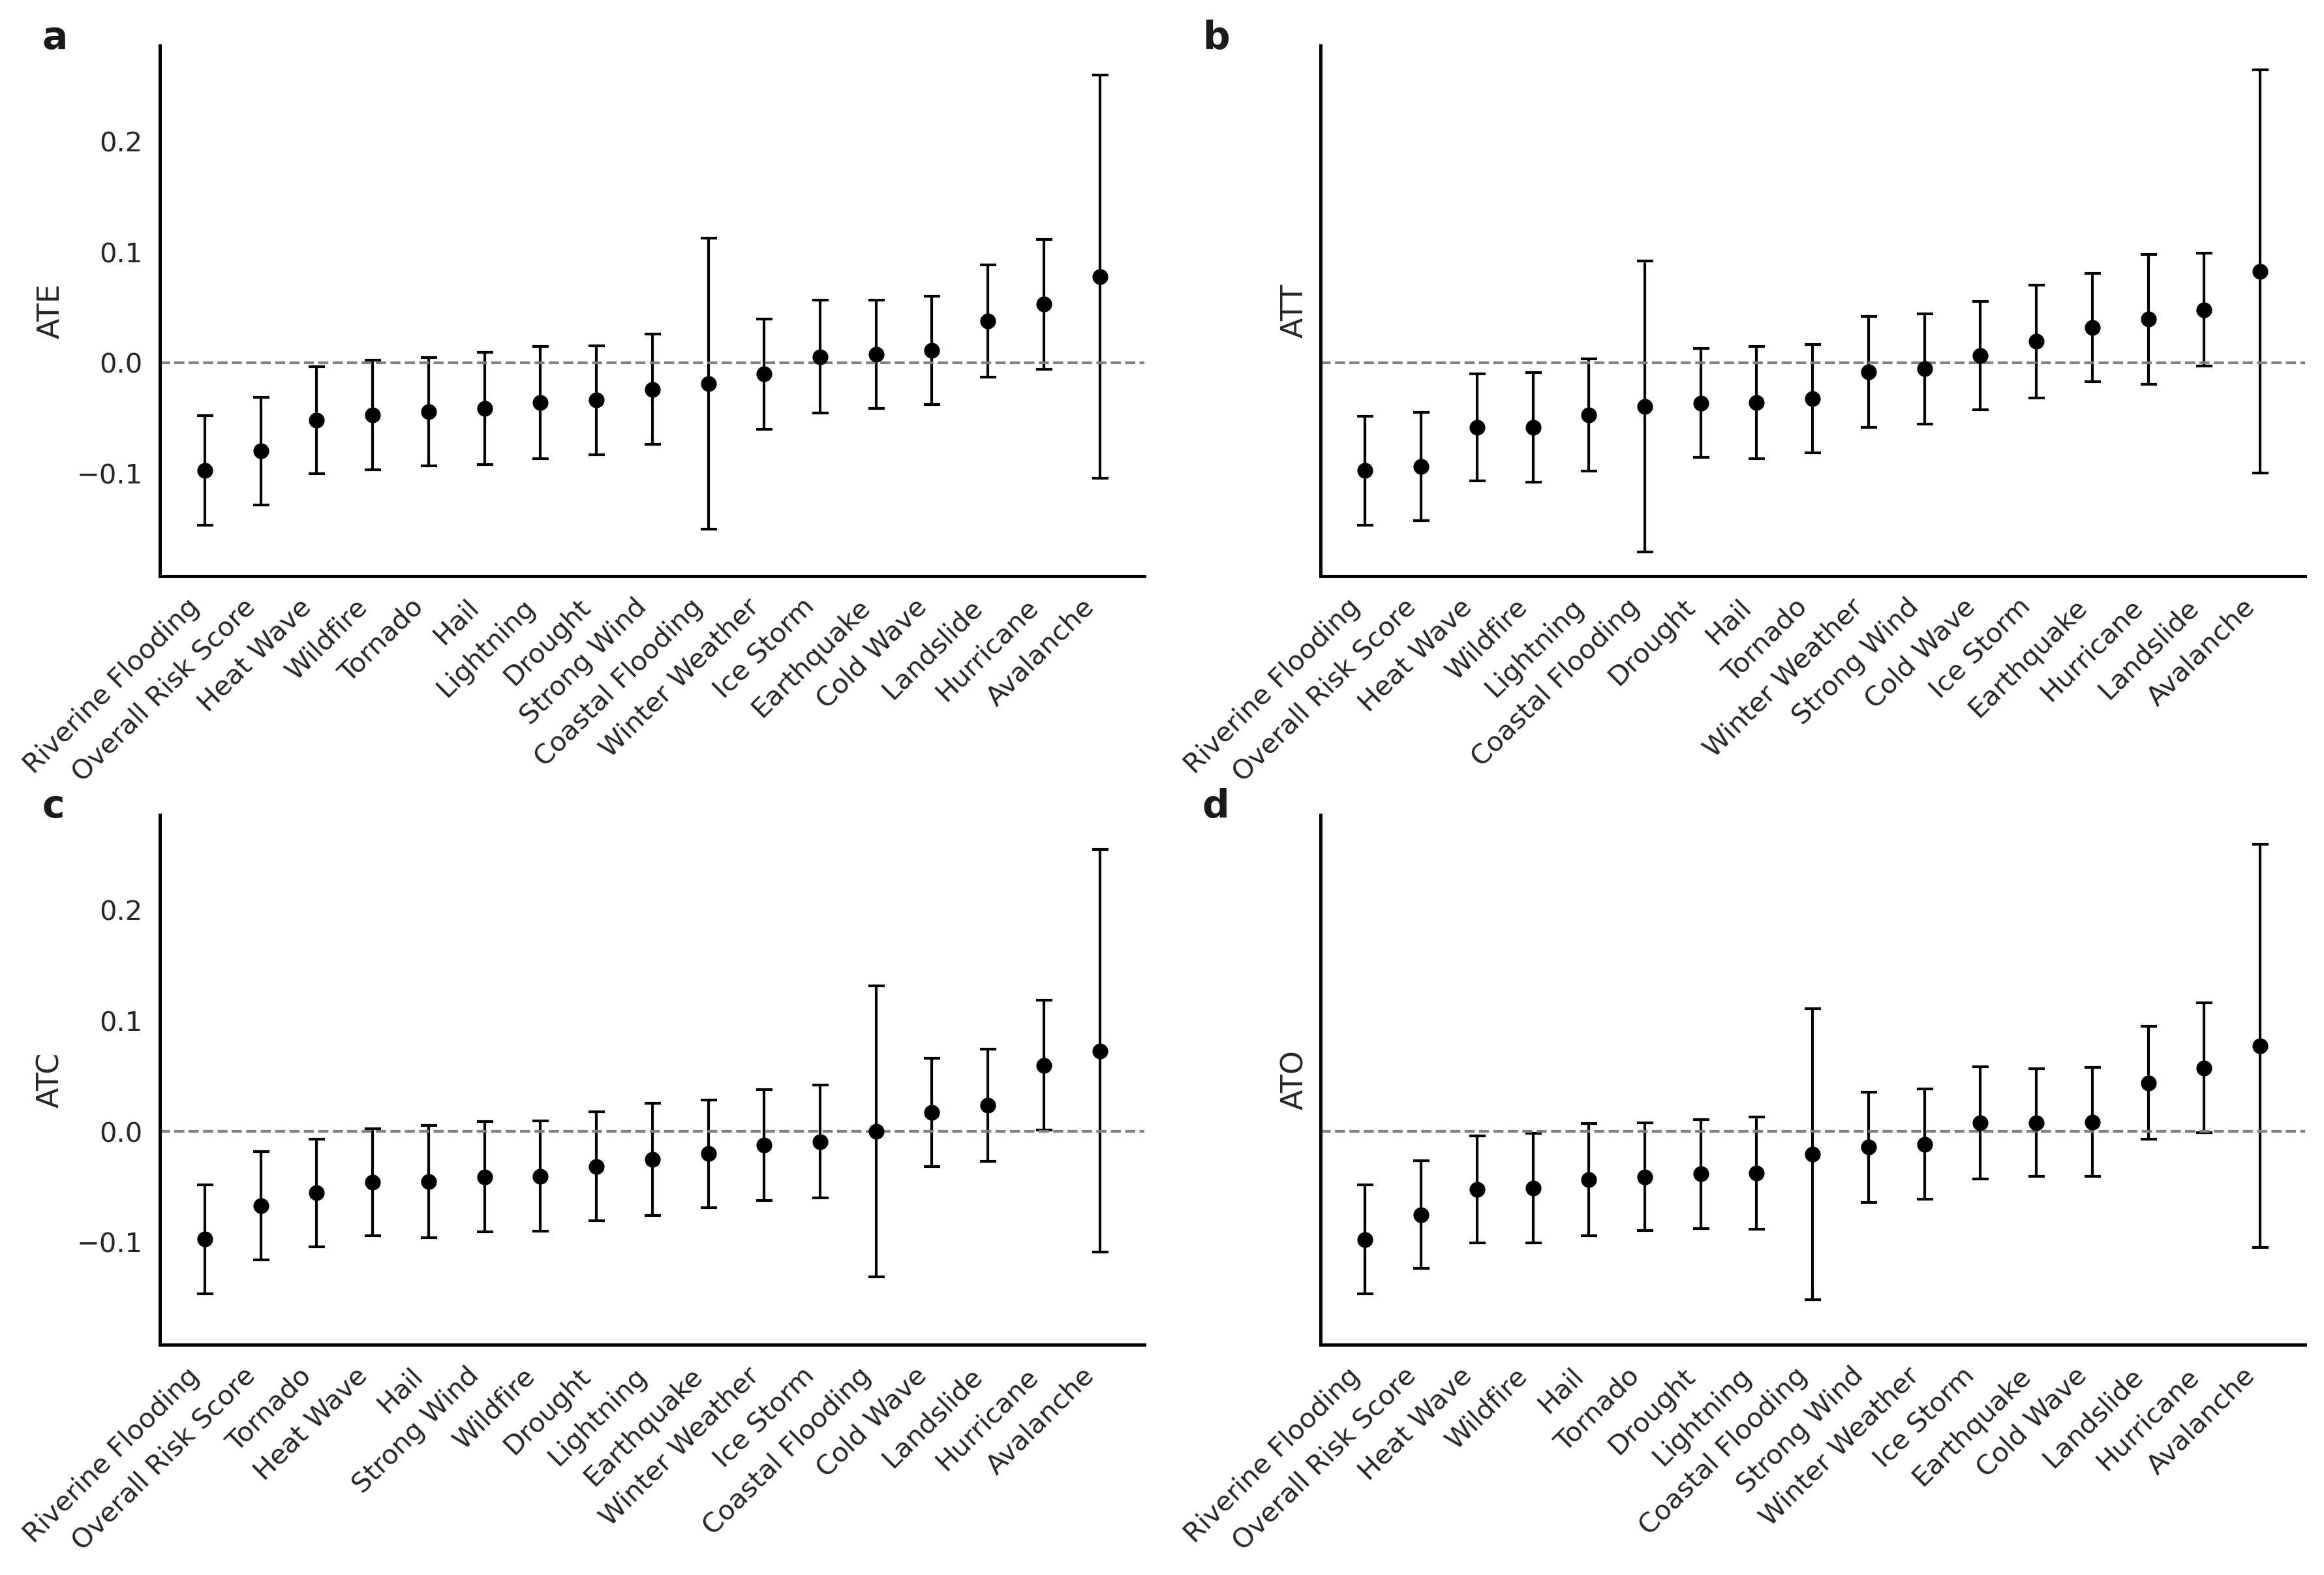

In [19]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharey=True
)

estimands = ["ATE", "ATT", "ATC", "ATO"]

for ax, est in zip(axes.flat, estimands):
    caterpillar_plot(
        df,
        estimand=f"{est}_est",
        ax=ax,
        title=est
    )

plt.tight_layout()

plots_l = ['a', 'b', 'c', 'd']
for ia, ax in enumerate(fig.axes): 
    x,y = -0.12,0.98
    ax.text(x,y,  plots_l[ia],
        color = 'k',#'lightgreen',
        horizontalalignment='left',
        verticalalignment='bottom',
        weight = 'bold',
        transform=ax.transAxes,fontsize = 14)

plt.savefig(
    '../fig/si/si_disasters_ate.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()


### Continuous case

In [20]:
cates_all=pd.read_csv('../data_generated/cf_results/cf_continuous_cates.csv')
cates_all=cates_all[cates_all['hazard']=='RISK_SCORE']
results_all=pd.read_csv('../data_generated/cf_results/cf_continuous_summary.csv')

In [21]:
vmax = cates_all["cate"].abs().quantile(0.95)
vmin = -vmax

norm = TwoSlopeNorm(
    vmin=vmin,
    vcenter=0.0,
    vmax=vmax
)

/tmp/ipykernel_17001/2783988872.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap("RdYlBu_r")


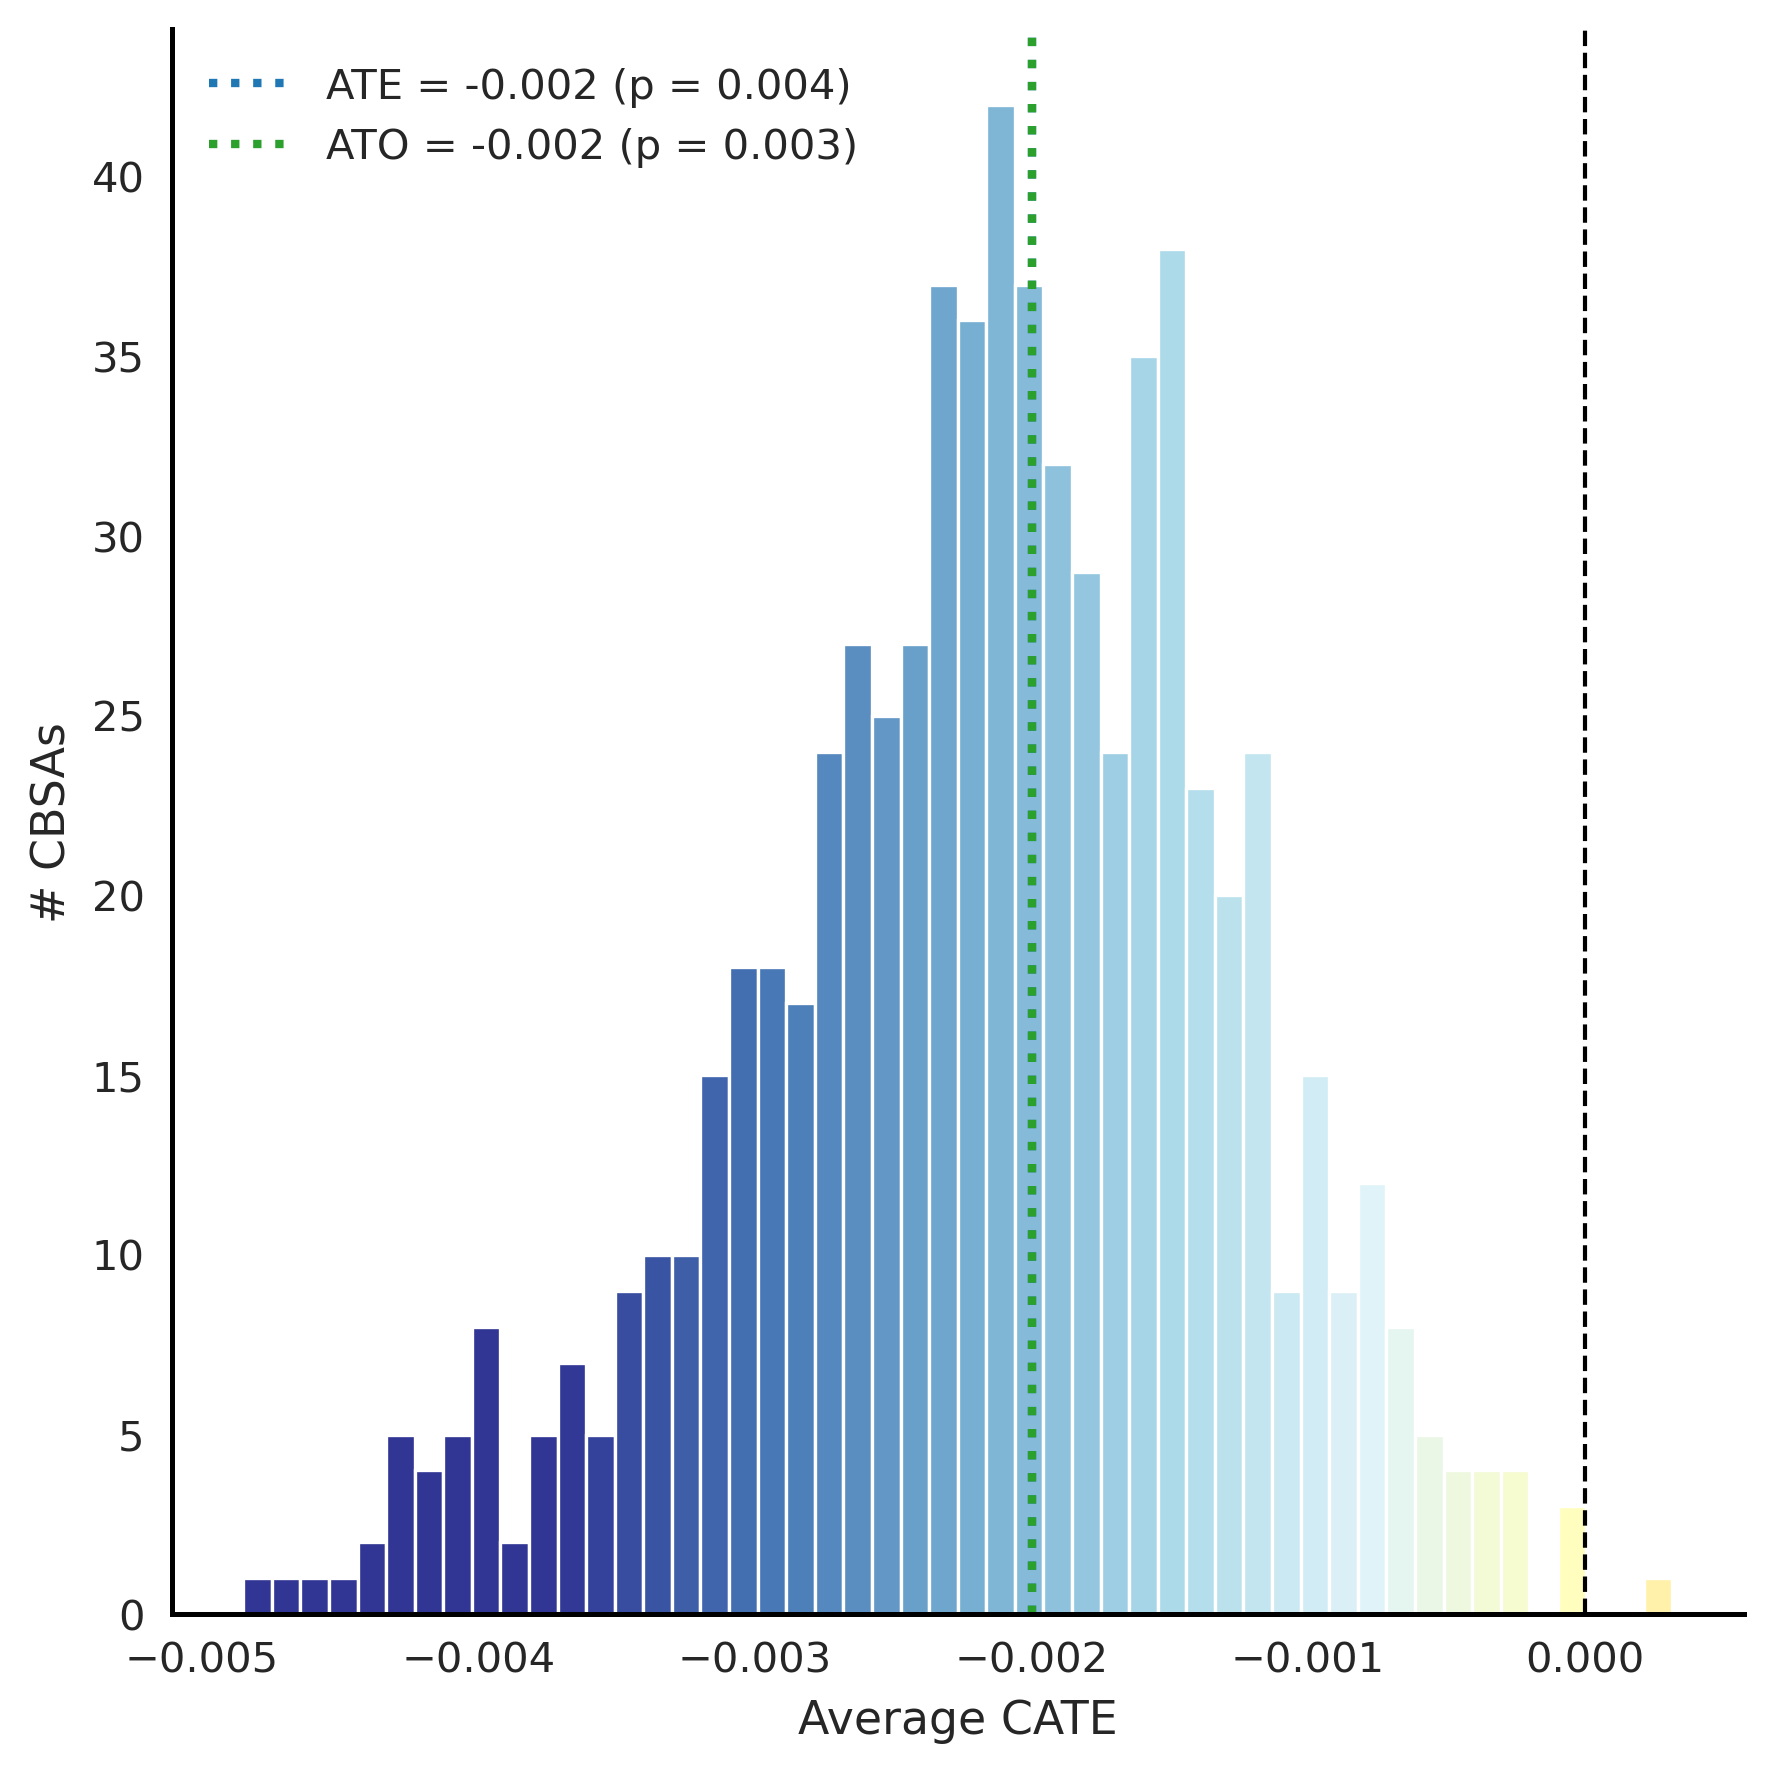

In [22]:
fig, ax = plt.subplots(figsize=(6, 6))

vals = cates_all["cate"].values

counts, bin_edges = np.histogram(vals, bins=50)

# compute bin midpoints (for color mapping)
bin_mids = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# get colors using the SAME norm + cmap as your colorbar
cmap = mpl.cm.get_cmap("RdYlBu_r")
colors = cmap(norm(bin_mids))

# plot histogram bars one by one
for left, height, width, color in zip(bin_edges[:-1], counts,
                                      np.diff(bin_edges), colors):
    ax.bar(left, height, width=width,
           color=color, edgecolor="white")

# zero line
ax.axvline(0, color="black", linewidth=1, linestyle="--")

ate=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATE_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATE_p'].iloc[0], 3)
ax.axvline(ate, lw=2, linestyle=":",
           label=f"ATE = {ate:.3f} (p = {p_val:.3f})",
           color="tab:blue")

ato=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATO_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATO_p'].iloc[0], 3)
ax.axvline(ato, lw=2, linestyle=":",
           label=f"ATO = {ato:.3f} (p = {p_val:.3f})",
           color="tab:green")

# labels and theme
ax.set_xlabel("Average CATE")
ax.set_ylabel("# CBSAs")
ax.set_title("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()

plt.show()

In [23]:
results_all["hazard"] = results_all["hazard"].map(NRI_HAZARD_NAMES)

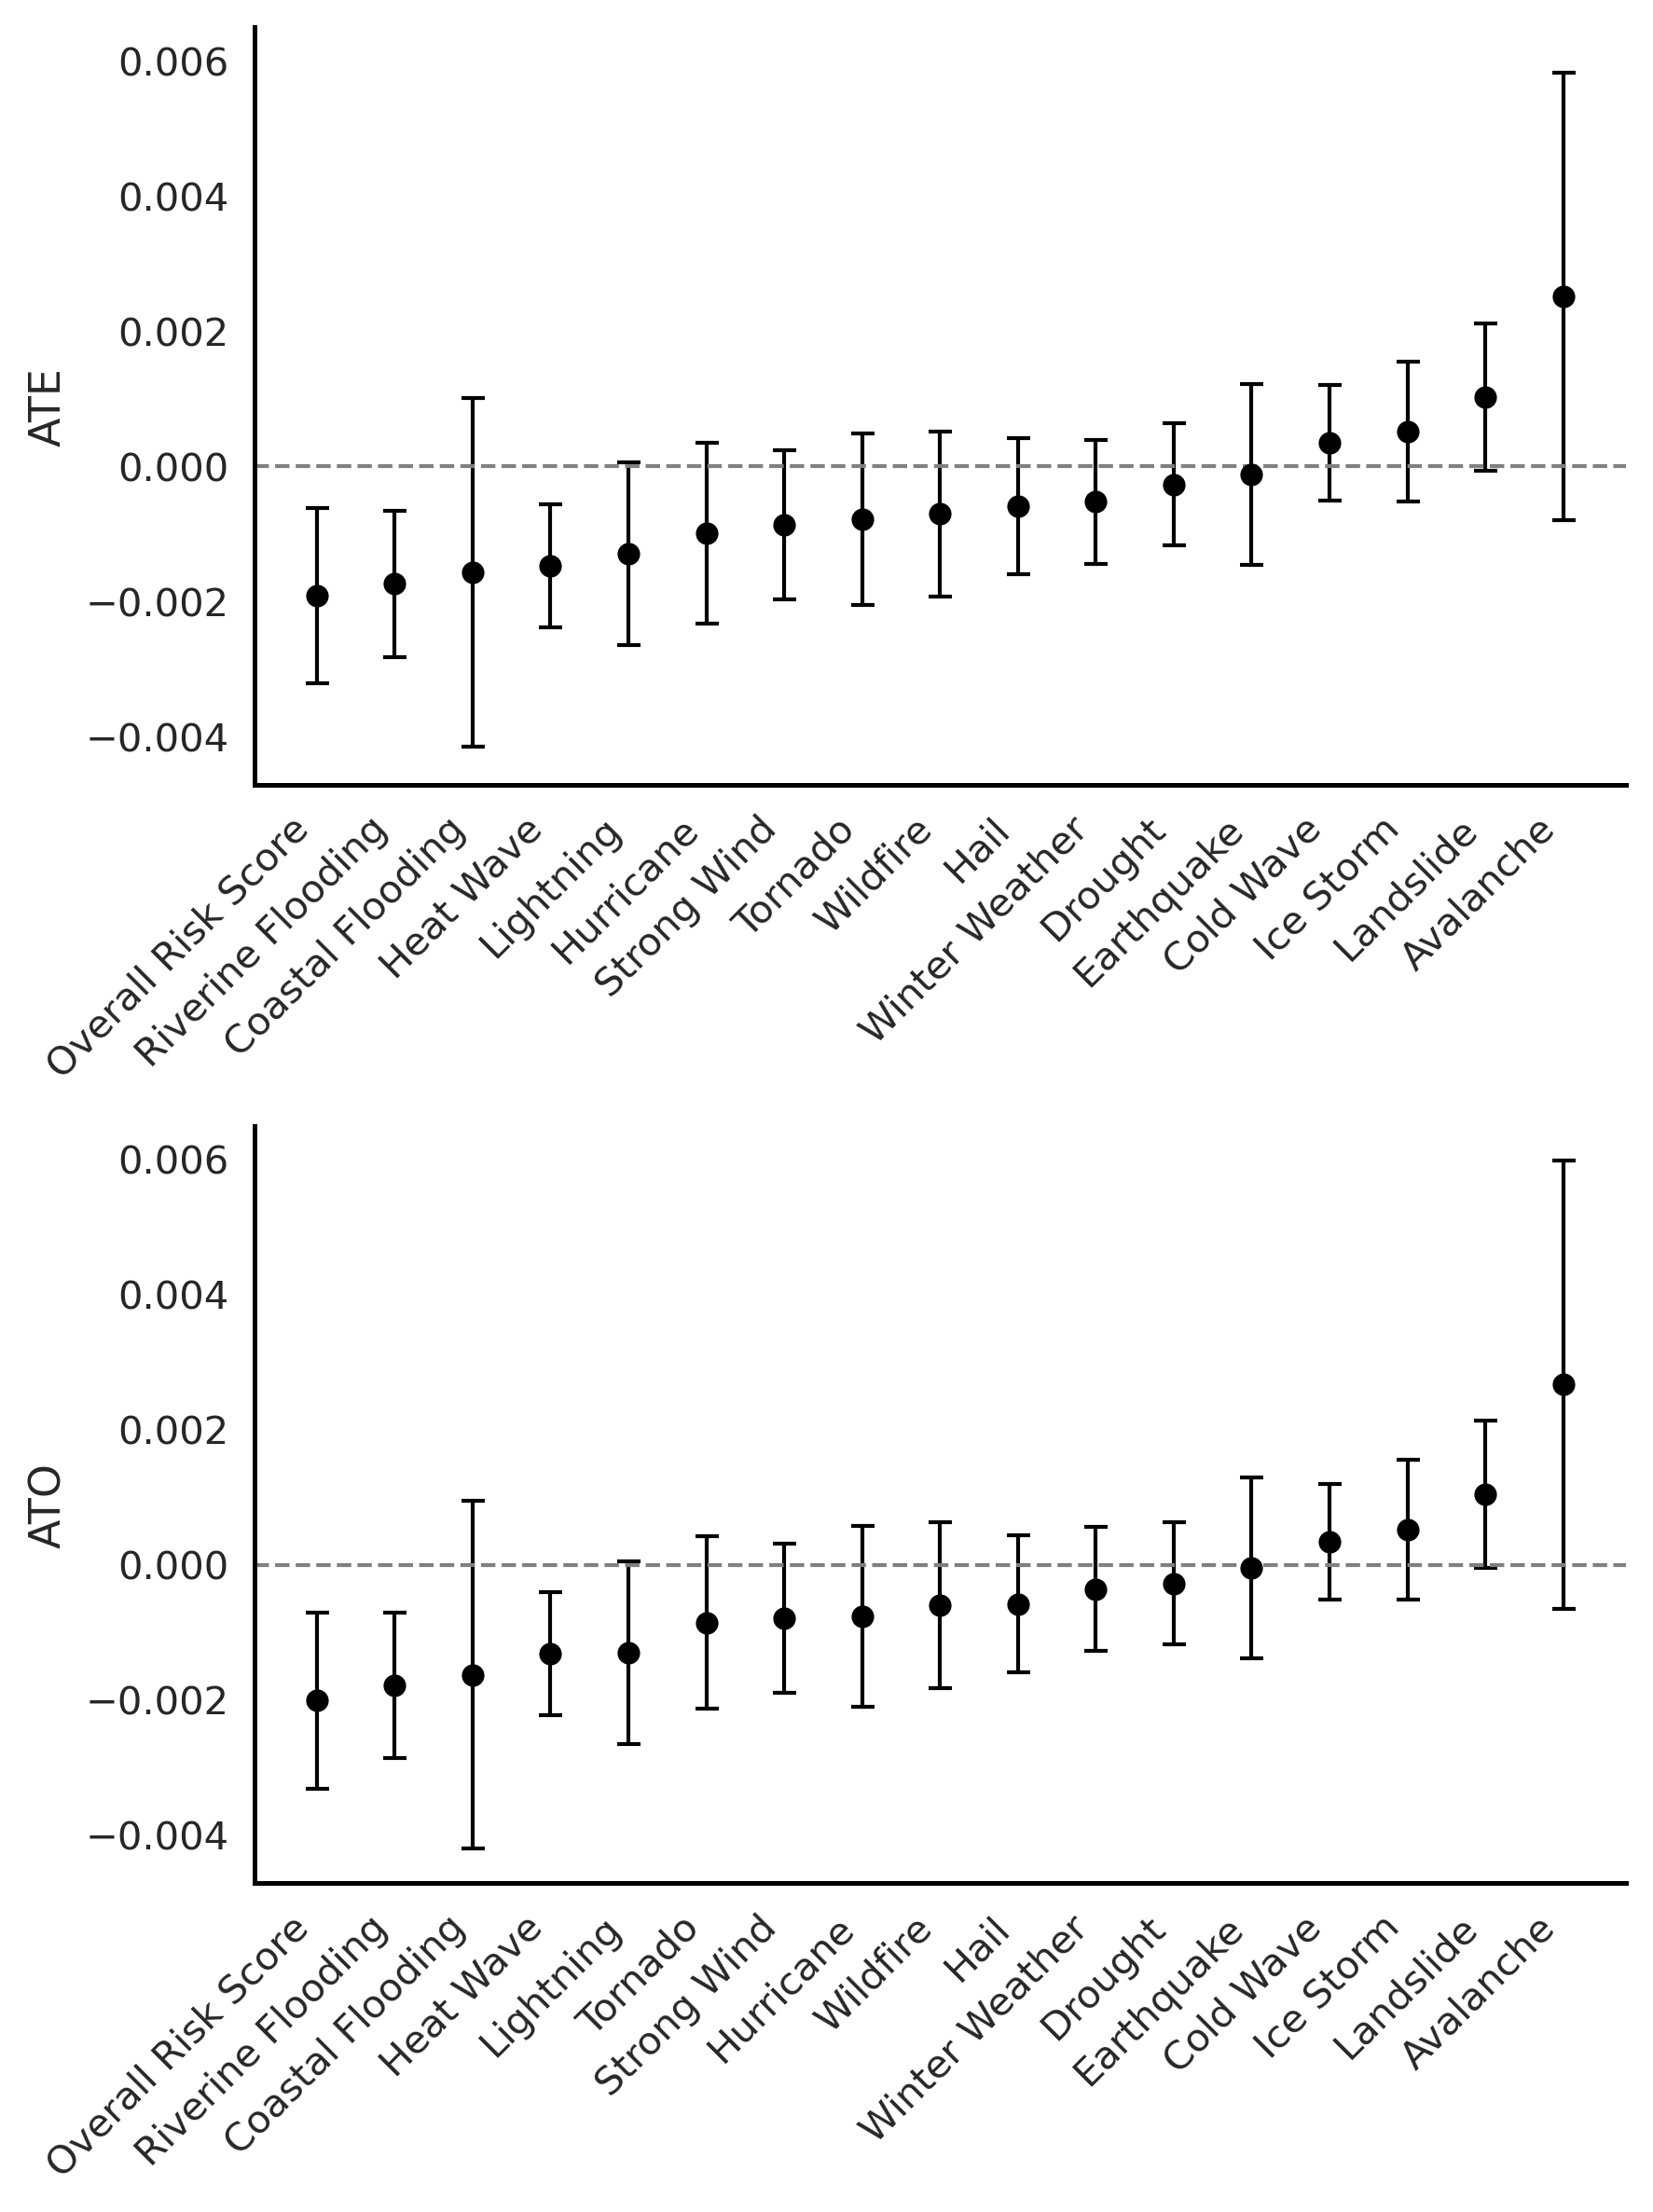

In [24]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(6, 8),
    sharey=True
)

estimands = ["ATE", "ATO"]

for ax, est in zip(axes.flat, estimands):
    caterpillar_plot(
        results_all,
        estimand=f"{est}_est",
        ax=ax,
        title=est
    )

plt.tight_layout()

# plots_l = ['', 'b']
# for ia, ax in enumerate(fig.axes): 
#     x,y = -0.12,0.98
#     ax.text(x,y,  plots_l[ia],
#         color = 'k',#'lightgreen',
#         horizontalalignment='left',
#         verticalalignment='bottom',
#         weight = 'bold',
#         transform=ax.transAxes,fontsize = 14)

plt.savefig(
    '../fig/si/si_disasters_continuous_ate.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()


### For SI-7: CBSA without probabilistic assignment

In [25]:
results_all=pd.read_csv('../data_generated/cf_results/si/cf_summary.csv')

In [26]:
df = results_all.copy()

df["hazard"] = df["hazard"].map(NRI_HAZARD_NAMES)

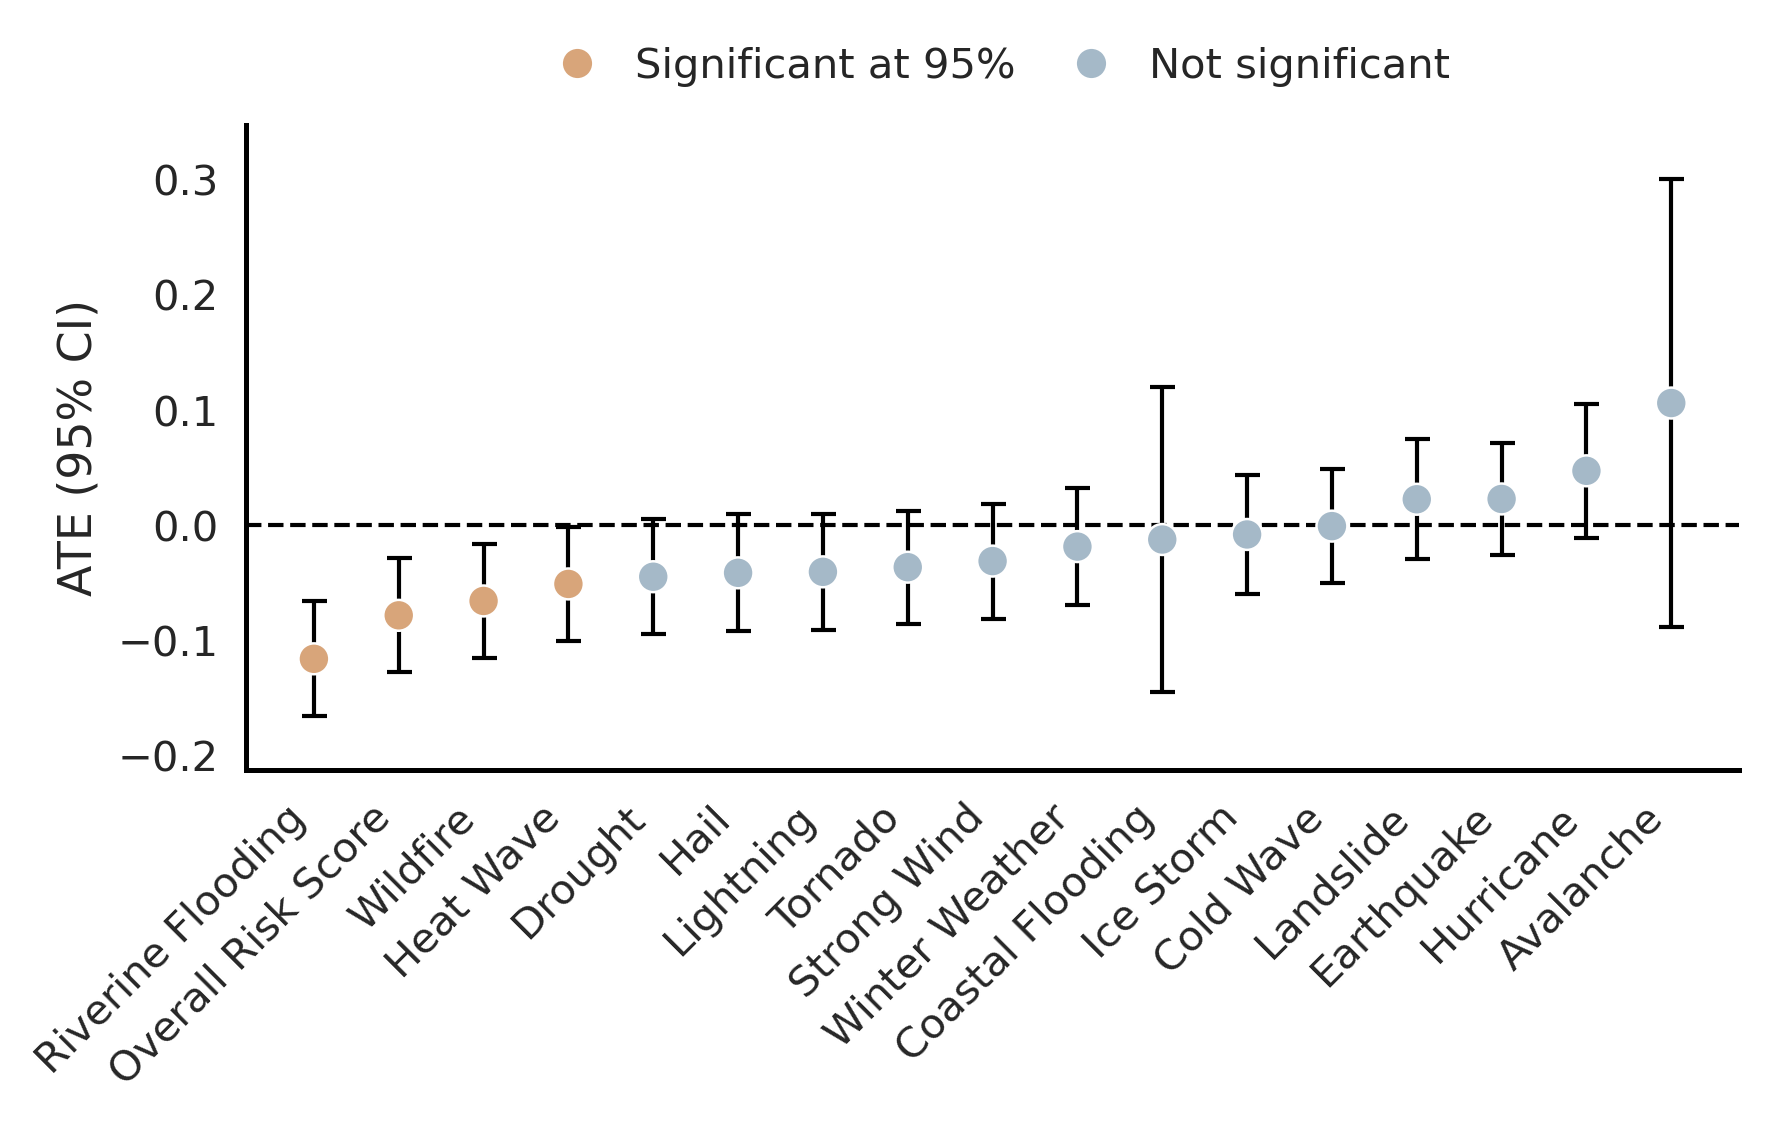

In [27]:
# keep hazards with ATE estimates
df = df[["hazard", "ATE_est", "ATE_se", "ATE_p"]].dropna().copy()

# 95% CI
z95 = 1.96
df["ci95_low"]  = df["ATE_est"] - z95 * df["ATE_se"]
df["ci95_high"] = df["ATE_est"] + z95 * df["ATE_se"]

# significance at 95%: CI excludes 0
df["sig95"] = (df["ci95_low"] > 0) | (df["ci95_high"] < 0)

# sort left->right by ATE
df = df.sort_values("ATE_est", ascending=True).reset_index(drop=True)

x = np.arange(len(df))

# ---- plot ----
fig, ax = plt.subplots(figsize=(6, 4))

# colors (muted)
c_nonsig = "#A5B9C8"  # muted blue
c_sig    = "#D8A57A"  # muted orange

colors = np.where(df["sig95"], c_sig, c_nonsig)

# vertical CI bars (because disasters are on x-axis)
yerr = z95 * df["ATE_se"].to_numpy()

ax.errorbar(
    x=x,
    y=df["ATE_est"].to_numpy(),
    yerr=yerr,
    fmt="o",
    markersize=6,
    capsize=3,
    linewidth=1,
    color="black", 
    ecolor="black",
    zorder=2
)

# overlay colored points to indicate significance
ax.scatter(
    x,
    df["ATE_est"].to_numpy(),
    s=55,
    c=colors,
    edgecolors="white",
    linewidths=0.6,
    zorder=3
)

# zero line
ax.axhline(0, linewidth=1.0, linestyle="--", color="black")

# x labels (hazards)
ax.set_xticks(x)
ax.set_xticklabels(df["hazard"], rotation=45, ha="right")

ax.set_ylabel("ATE (95% CI)")

# y-limits with padding
ymin = (df["ci95_low"]).min()
ymax = (df["ci95_high"]).max()
pad = 0.10 * (ymax - ymin) if ymax > ymin else 0.1
ax.set_ylim(ymin - pad, ymax + pad)

# minimalist styling
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

# legend (top, horizontal)
from matplotlib.lines import Line2D
handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=c_sig, markeredgecolor="white",
           markersize=8, label="Significant at 95%"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=c_nonsig, markeredgecolor="white",
           markersize=8, label="Not significant")
]
ax.legend(
    handles=handles,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=2,
    columnspacing=0.8,
    handletextpad=0.4
)

plt.tight_layout()
plt.show()

In [28]:
cates_all=pd.read_csv('../data_generated/cf_results/si/cf_cates.csv')
cates_all=cates_all[cates_all['hazard']=='RISK_SCORE']

In [29]:
vmax = cates_all["cate"].abs().quantile(0.95)
vmin = -vmax

norm = TwoSlopeNorm(
    vmin=vmin,
    vcenter=0.0,
    vmax=vmax
)

/tmp/ipykernel_17001/2895249298.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap("RdYlBu_r")


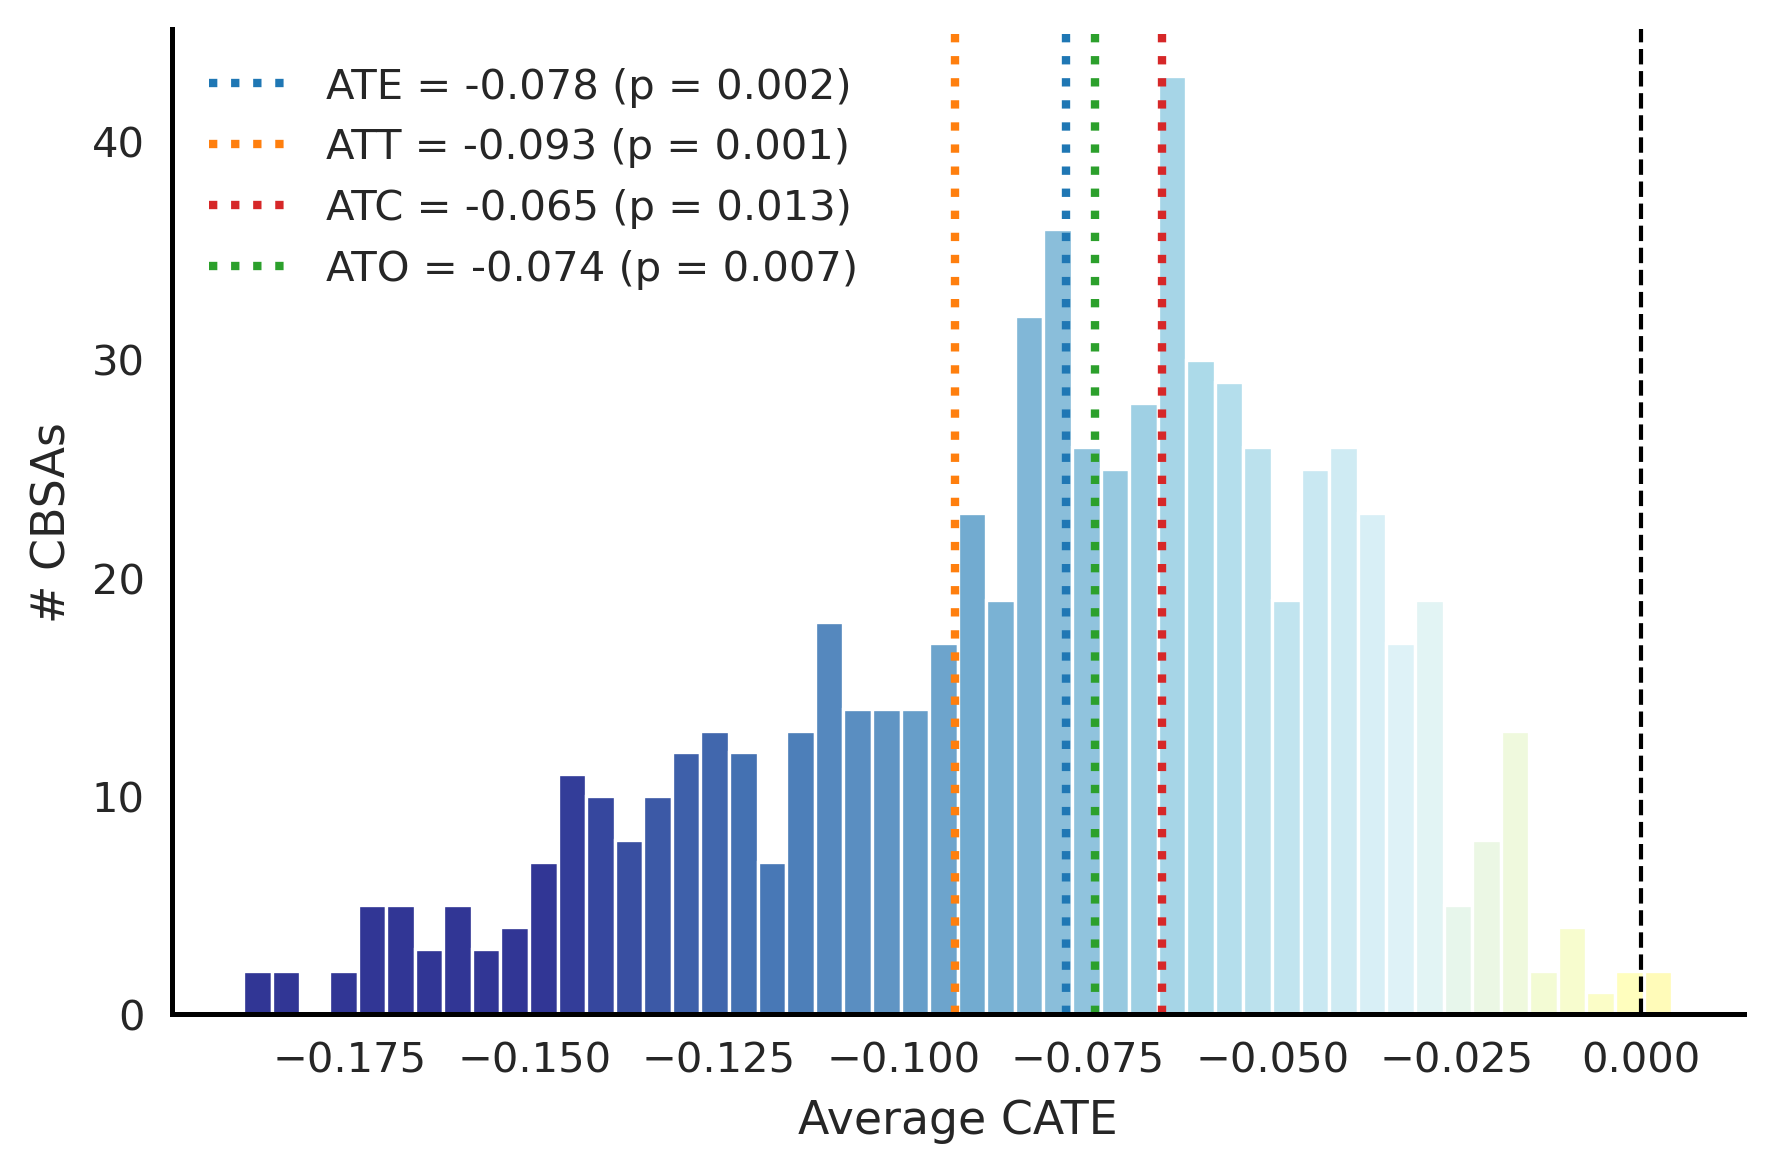

In [30]:
fig, ax = plt.subplots(figsize=(6, 4))
# fig, ax = plt.subplots(figsize=(6, 6))

vals = cates_all["cate"].values

counts, bin_edges = np.histogram(vals, bins=50)

# compute bin midpoints (for color mapping)
bin_mids = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# get colors using the SAME norm + cmap as your colorbar
cmap = mpl.cm.get_cmap("RdYlBu_r")
colors = cmap(norm(bin_mids))

# plot histogram bars one by one
for left, height, width, color in zip(bin_edges[:-1], counts,
                                      np.diff(bin_edges), colors):
    ax.bar(left, height, width=width,
           color=color, edgecolor="white")

# zero line
ax.axvline(0, color="black", linewidth=1, linestyle="--")

ate=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATE_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATE_p'].iloc[0], 3)
ax.axvline(ate, lw=2, linestyle=":",
           label=f"ATE = {ate:.3f} (p = {p_val:.3f})",
           color="tab:blue")

att=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATT_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATT_p'].iloc[0], 3)
ax.axvline(att, lw=2, linestyle=":",
           label=f"ATT = {att:.3f} (p = {p_val:.3f})",
           color="tab:orange")

atc=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATC_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATC_p'].iloc[0], 3)
ax.axvline(atc, lw=2, linestyle=":",
           label=f"ATC = {atc:.3f} (p = {p_val:.3f})",
           color="tab:red")

ato=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATO_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATO_p'].iloc[0], 3)
ax.axvline(ato, lw=2, linestyle=":",
           label=f"ATO = {ato:.3f} (p = {p_val:.3f})",
           color="tab:green")

# labels and theme
ax.set_xlabel("Average CATE")
ax.set_ylabel("# CBSAs")
ax.set_title("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()

plt.show()

In [31]:
variable_importance=pd.read_csv('../data_generated/cf_results/si/cf_varimp.csv')
variable_importance=variable_importance[variable_importance['hazard']=='RISK_SCORE']

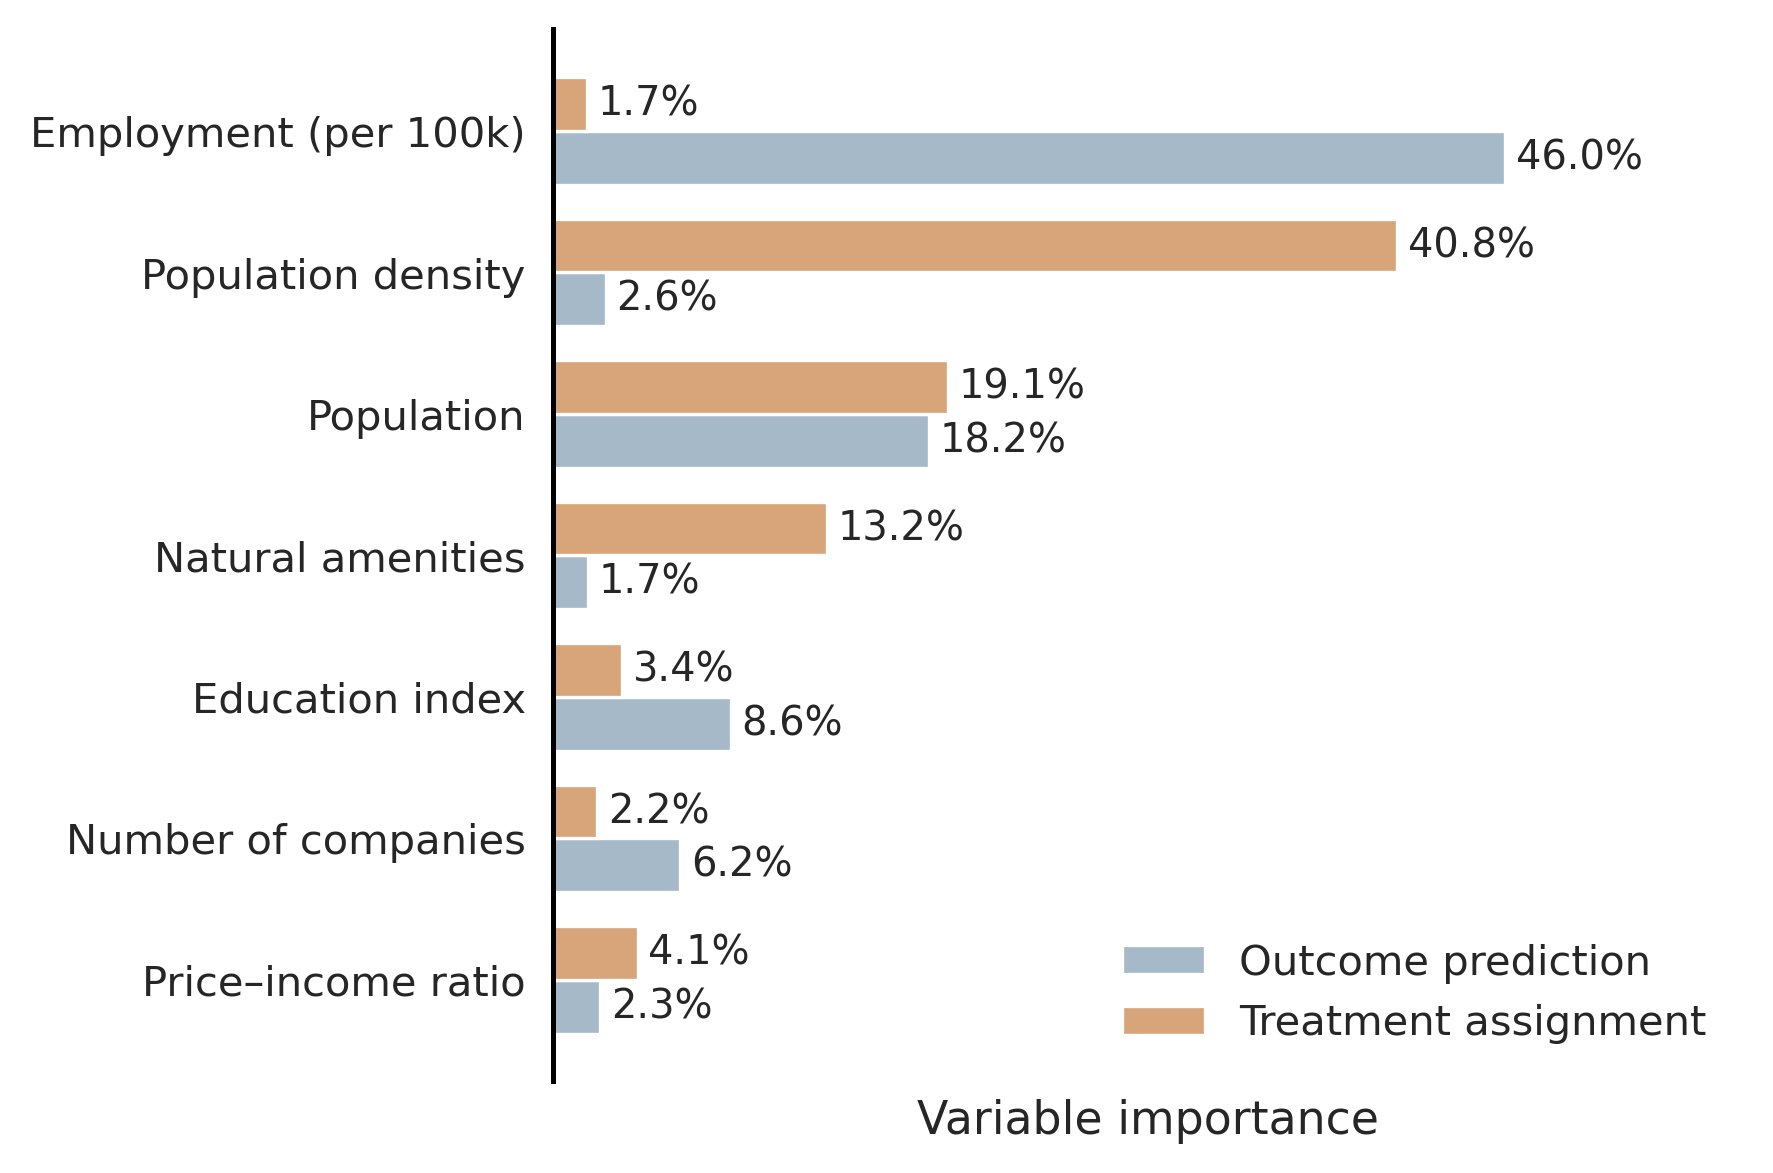

In [32]:
# Rename variables for readability
rename_map = {
    "nat_amenity_score": "Natural amenities",
    "state": "State FE",
    "income_price_ratio2023": "Price–income ratio",
    "gdp_pc": "GDP pc",
    "income_index_adj": "Income index",
    "real_estate_taxes_med": "Property taxes",
    "est_100k": "Number of companies",
    "POPULATION": "Population",
    "health_index_adj": "Health index",
    "personal_income_pc": "Personal income pc",
    "inequality_ratio": "Inequality ratio",
    "education_index": "Education index",
    "n_postings_100k": "Job postings (per 100k)",
    "emp_100k": "Employment (per 100k)",
    "poverty_rate_all": "Poverty rate",
    "pop_density": "Population density",
    "dividends_pc": "Dividends pc"
}

# keep only the two nuisance models
df = variable_importance.copy()
df = df[(df["hazard"] == "RISK_SCORE") & (df["model"].isin(["Y_nuisance", "W_nuisance"]))]

# mean importance by nuisance x variable
imp = (
    df.groupby(["model", "variable"], as_index=False)["importance"]
      .mean()
)

# top-7 variables by overall mean across nuisances
top_vars = (
    imp.groupby("variable")["importance"]
       .mean()
       .sort_values(ascending=False)
       .head(7)
       .index
)

imp_top = imp[imp["variable"].isin(top_vars)].copy()

# nice names + pivot wide for plotting
imp_top["variable_name"] = imp_top["variable"].map(lambda v: rename_map.get(v, v))

wide = (
    imp_top.pivot_table(index="variable_name", columns="model", values="importance", aggfunc="mean")
           .fillna(0.0)
)

# ensure consistent column order
for col in ["Y_nuisance", "W_nuisance"]:
    if col not in wide.columns:
        wide[col] = 0.0
wide = wide[["Y_nuisance", "W_nuisance"]]

# order: smallest at top for barh (so reverse later if you want)
wide["overall"] = wide.mean(axis=1)
wide = wide.sort_values("overall", ascending=True).drop(columns="overall")

# ---- Plot: grouped horizontal bars ----
fig, ax = plt.subplots(figsize=(6, 4))

y = np.arange(len(wide.index))
h = 0.38

vals_y = wide["Y_nuisance"].values * 100
vals_w = wide["W_nuisance"].values * 100

ax.barh(y - h/2, vals_y, height=h, label="Outcome prediction", color="#A5B9C8")
ax.barh(y + h/2, vals_w, height=h, label="Treatment assignment", color="#D8A57A")

# labels on bars
for i, v in enumerate(vals_y):
    ax.text(v + 0.5, y[i] - h/2, f"{v:.1f}%", va="center")
for i, v in enumerate(vals_w):
    ax.text(v + 0.5, y[i] + h/2, f"{v:.1f}%", va="center")

ax.set_yticks(y)
ax.set_yticklabels(wide.index)
ax.set_xlabel("Variable importance")

xmax = max(vals_y.max(), vals_w.max())
ax.set_xlim(0, xmax * 1.25)

ax.legend(frameon=False, loc="lower right")

# REMOVE x-axis ticks
ax.set_xticks([])

sns.despine(left=False, bottom=True)

plt.tight_layout()
plt.show()

In [33]:
subgroups=pd.read_csv('../data_generated/cf_results/si/cf_subgroups.csv')
subgroups=subgroups[subgroups['hazard']=='RISK_SCORE']

In [34]:
# ---- Rename variables for readability ----
rename_map = {
    "Natural Amenities": "Natural amenities",
    "Population Density": "Population density",
    "Price-Income": "Price–income ratio",
    "GDP per Capita": "GDP pc",
    "income_index_adj": "Income index",
    "real_estate_taxes_med": "Property taxes",
    "est_100k": "Number of companies",
    "Population": "Population",
    "health_index_adj": "Health index",
    "personal_income_pc": "Personal income pc",
    "inequality_ratio": "Inequality ratio",
    "Education Index": "Education index",
    "n_postings_100k": "Job postings (per 100k)",
    "Number of Employed": "Employment (per 100k)",
    "poverty_rate_all": "Poverty rate",
    "pop_density": "Population density",
    "dividends_pc": "Dividends pc"
}

subgroups["moderator"] = subgroups["moderator"].map(lambda v: rename_map.get(v, v))

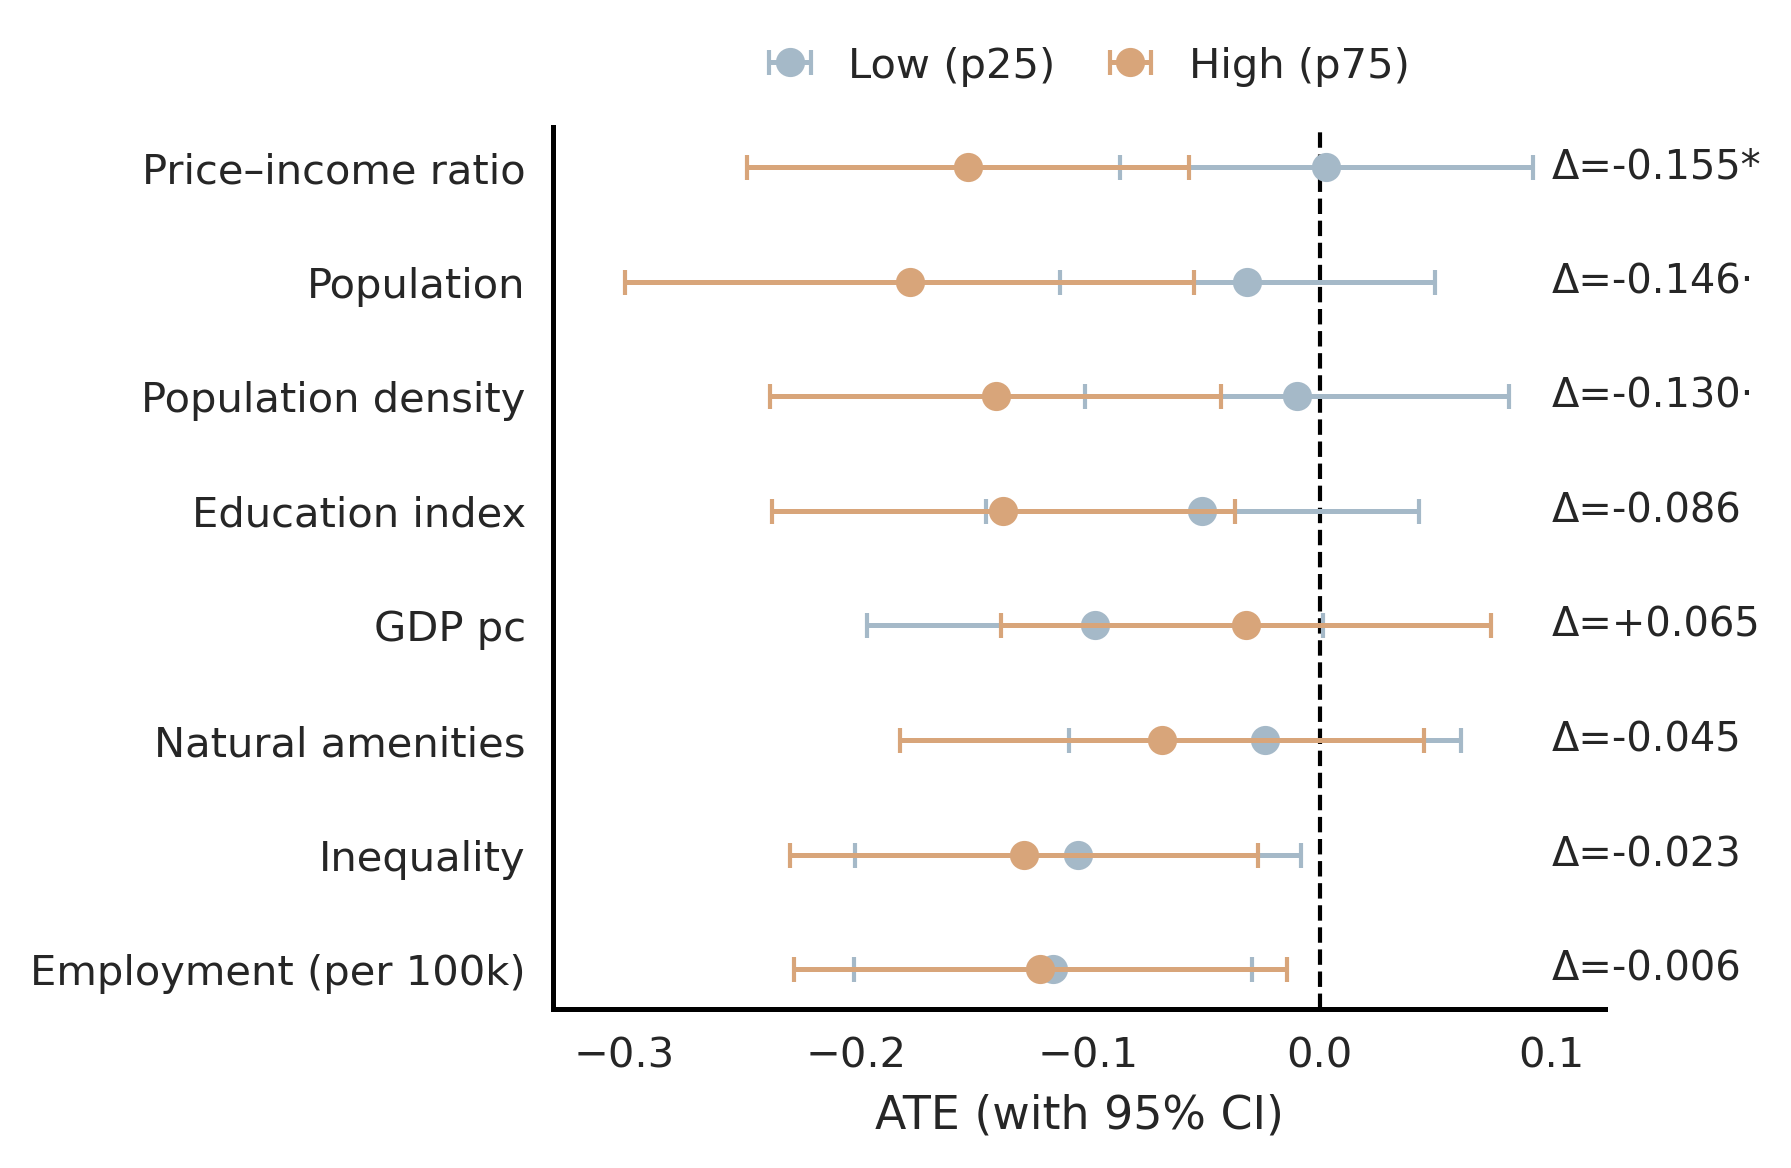

In [35]:
# ---- filter to 25/75 splits for the hazard of interest ----
df = subgroups.copy()
df = df[(df["hazard"] == "RISK_SCORE") & (df["split_type"] == "p25/p75")].copy()

# order (optional): by absolute diff or by diff estimate
df["abs_diff"] = df["diff_est"].abs()
df = df.sort_values("abs_diff", ascending=True)

# labels
y_labels = df["moderator"].astype(str).tolist()
y = np.arange(len(df))

# values + 95% CI
low = df["ATE_low_est"].to_numpy()
high = df["ATE_high_est"].to_numpy()

low_se = df["ATE_low_se"].to_numpy()
high_se = df["ATE_high_se"].to_numpy()

low_ci = 1.96 * low_se
high_ci = 1.96 * high_se

# optional: stars for diff p-value
def stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    if p < 0.1:
        return "·"
    return ""

df["diff_star"] = df["diff_p"].apply(stars)

# ---- plot ----
fig, ax = plt.subplots(figsize=(6, 4))

# muted colors (blue vibe + your muted orange vibe)
c_low = "#A5B9C8"
c_high = "#D8A57A"

# connecting lines
for i in range(len(df)):
    ax.plot([low[i], high[i]], [y[i], y[i]], linewidth=1.2, zorder=1)

# error bars + points
ax.errorbar(low, y, xerr=low_ci, fmt="o", markersize=6, capsize=3,
            linewidth=1.2, color=c_low, label="Low (p25)", zorder=3)

ax.errorbar(high, y, xerr=high_ci, fmt="o", markersize=6, capsize=3,
            linewidth=1.2, color=c_high, label="High (p75)", zorder=4)

# vertical zero line
ax.axvline(0, color="black", linewidth=1, linestyle="--")

# y-axis labels
ax.set_yticks(y)
ax.set_yticklabels(y_labels)

ax.set_xlabel("ATE (with 95% CI)")

# x-limits with padding
xmin = np.min(np.r_[low - low_ci, high - high_ci])
xmax = np.max(np.r_[low + low_ci, high + high_ci])
pad = 0.08 * (xmax - xmin) if xmax > xmin else 0.1
ax.set_xlim(xmin - pad, xmax + pad)

# annotate difference at right side
x_annot = 0.1
for i in range(len(df)):
    d = df.iloc[i]["diff_est"]
    p = df.iloc[i]["diff_p"]
    s = df.iloc[i]["diff_star"]
    ax.text(x_annot, y[i], f"Δ={d:+.3f}{s}", va="center", ha="left")

# styling
ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.12),  # move slightly above plot
    ncol=2,                       # horizontal layout
    columnspacing=0.8,   # ↓ reduce space between columns (default ≈ 2.0)
    handletextpad=0.4,   # ↓ reduce space between marker and text
    borderaxespad=0.2
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

plt.tight_layout()
plt.show()